<a href="https://colab.research.google.com/github/GeorgiosMavrakis/introduction-to-github/blob/main/V%26L_Practicum_Uncertainty.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Practicum Vision & Language NLP - Uncertainty Quantification with Multimodal LLMs

In this notebook, we will evaluate several multimodal Vision & Language LLMs on a Medical Visual Question Answering task. We will use the following dataset: [GMAI-MMBench: A Comprehensive Multimodal Evaluation Benchmark Towards General Medical AI.](https://huggingface.co/datasets/OpenGVLab/GMAI-MMBench) The dataset is released under the Apache 2.0 license, and you will work on a pre-processed subset prepared by us.

We will evaluate several models:
- `Qwen2-VL-2B-Instruct` and `Medgemma-4b-it` (smaller models that can be run directly on Colab; output files are also provided in case of issues).
- `Qwen2.5-VL-32B-Instruct` and `GPT-5-mini` (larger models - we provide the output files).

Output files are named according to the following template:
`outputs_{model_name}-sample_{sample_answers}-temp_{temperature}.tsv`

### Setup

- In Runtime, select Change runtime type, then choose **T4 GPU** as the hardware accelerator.  

- Log into Hugging Face and accept the license agreement for [Qwen2-VL-2B-Instruct](https://huggingface.co/Qwen/Qwen2-VL-2B-Instruct) and [Medgemma-4b-it](https://huggingface.co/google/medgemma-4b-it). Attention, this may take a while to be processed.

- Set your Hugging Face token as the variable **HF_TOKEN** in the Secrets tab (left menu, key icon) or paste your token in the "your_token" in the required field. Make sure not to accidentaly share it.


### Important Note

This challenging assignment gives you plenty of freedom to explore and be creative. You are expected to demonstrate independence, formulate your own hypotheses, and test them empirically. Since this is a cutting-edge research area with many open questions, take the opportunity to investigate, experiment, and follow your curiosity! :)


In [13]:
from typing import List, Dict, Any, Tuple, Generator, Optional, Union
import random
import string, os, sys, glob
import pandas as pd
import numpy as np
from google.colab import userdata

from PIL import Image
from tqdm import tqdm
import torch
import ast
import matplotlib.pyplot as plt


In [ ]:
try:
  hf_token = userdata.get('HF_TOKEN')
except userdata.SecretNotFoundError:
  hf_token = "your_token"

os.environ["HF_TOKEN"] = hf_token

In [ ]:
!gdown --folder https://drive.google.com/drive/folders/1dNoFV9GvDhMdTjM2P2oHW00-f9oPMxnf -O /content/data # download pre-processed dataset files + model responses
!unzip -q data/filtered_images.zip -d data/images/ # unzip the images folder

Retrieving folder contents
Retrieving folder 1MxSEpKZWI26Gl2dVdvRd2uMn7Eimr9dC model_responses
Processing file 1tG8zYy11gXQ-puRQocji6OOKogHR12Pi outputs_gpt5-mini_no-logprobs.tsv
Processing file 1GVFn2qKdDJxtEbbrufC0W7eULvAZMyPa outputs_medgemma-4b-it-temp_0.2.tsv
Processing file 1BAx2jUeuUbgRX6joWR94vdS0nsqCNf-I outputs_medgemma-4b-it-temp_0.6.tsv
Processing file 1JK7ACAkPVKIyEZ39RtVru3GDgUvMk_8J outputs_medgemma-4b-it-temp_1.0.tsv
Processing file 18cSUZl93yG167twxUY_gmEaMYXDOfi3q outputs_Qwen2-VL-2B-Instruct-temp_0.2.tsv
Processing file 1pxUlsk9rK67Uo9mOSxKKOebMzGxPYXS9 outputs_Qwen2-VL-2B-Instruct-temp_0.6.tsv
Processing file 1WlgSroLtv5STSufSC4qRM419KW5YRBod outputs_Qwen2-VL-2B-Instruct-temp_1.0.tsv
Processing file 1HjbP_JjNq1gkqsz-RiXff-c5M_tvPvb8 outputs_Qwen2.5-VL-32B-Instruct-temp_0.2.tsv
Processing file 11XjxhRI7j-xOEtnTYnE7-v8pFTOk6jIh outputs_Qwen2.5-VL-32B-Instruct-temp_0.6.tsv
Processing file 1FSfXTQj2ytMsCfO0Iy_xoeP0P-IqI-K7 outputs_Qwen2.5-VL-32B-Instruct-temp_1.0.tsv
Pr

In [ ]:
!ls data data/model_responses

pd.set_option("display.max_colwidth", None)
ds = pd.read_csv("data/GMAI_mm_bench_dataset.tsv", sep="\t")  # separate name so df is not overwritten
print(ds.columns.tolist())
print(ds.iloc[0])

for p in sorted(glob.glob("data/model_responses/*.tsv")):
    r = pd.read_csv(p, sep="\t")
    print(os.path.basename(p), r.shape, r.columns.tolist())

print(pd.read_csv(sorted(glob.glob("data/model_responses/*Qwen2-VL-2B*.tsv"))[0], sep="\t").iloc[0])

data:
filtered_images.zip  GMAI_mm_bench_dataset.tsv	images	model_responses

data/model_responses:
outputs_gpt5-mini_no-logprobs.tsv
outputs_medgemma-4b-it-temp_0.2.tsv
outputs_medgemma-4b-it-temp_0.6.tsv
outputs_medgemma-4b-it-temp_1.0.tsv
outputs_Qwen2.5-VL-32B-Instruct-temp_0.2.tsv
outputs_Qwen2.5-VL-32B-Instruct-temp_0.6.tsv
outputs_Qwen2.5-VL-32B-Instruct-temp_1.0.tsv
outputs_Qwen2-VL-2B-Instruct-temp_0.2.tsv
outputs_Qwen2-VL-2B-Instruct-temp_0.6.tsv
outputs_Qwen2-VL-2B-Instruct-temp_1.0.tsv
['index', 'question', 'A', 'B', 'C', 'D', 'E', 'answer', 'category', 'clinical VQA task', 'department', 'perceptual granularity', 'modality', 'original task', 'image_path']
index                                                                                                  398
question                  Which of the following options best matches the marked organ in the X-ray image?
A                                                                       fascia uncovered kidney parenchyma
B   

# 1. Inference (run on GPUs)

## Load and Prepare Model Inputs

In [ ]:
def add_options_dict(df_raw: pd.DataFrame) -> pd.DataFrame:  # prepare the multiple-choice question format
    option_cols = [col for col in df_raw.columns if col in list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")]

    def _make_dict(row):
        return {col: row[col] for col in option_cols if pd.notna(row[col])}

    out = df_raw.copy()
    out["options"] = out.apply(_make_dict, axis=1)
    return out

def construct_prompt(row) -> str:  # prepare the prompt for the model
    PROMPT_TEMPLATE = """Question: ({question})
Provide a concise answer and start your response with the letter of the selected option in square brackets. Options:
(
{options}
)
Your Answer:
"""
    question = row["question"]
    options = {
        letter: row[letter]
        for letter in string.ascii_uppercase[:5]
        if letter in row and row[letter] and str(row[letter]).strip() and not pd.isna(row[letter])
    }

    formatted_options = "\n".join(
        f"[{letter}] {option}"
        for letter, option in options.items()
    )

    return PROMPT_TEMPLATE.format(
        question=question,
        options=formatted_options
    )

In [ ]:
input_tsv = "data/GMAI_mm_bench_dataset.tsv"  # the pre-processed dataset we provide
df = pd.read_csv(input_tsv, sep="\t")

df = add_options_dict(df)
df["prompt"] = df.apply(lambda row: construct_prompt(row), axis=1)
data_records: List[dict] = df.to_dict(orient="records")

In [ ]:
df.head()  # inspect the data

,index,question,A,B,C,D,E,answer,category,clinical VQA task,department,perceptual granularity,modality,original task,image_path,options,prompt
0,398,Which of the following options best matches the marked organ in the X-ray image?,fascia uncovered kidney parenchyma,lung,fascia covered kidney parenchyma,heart,clavicles,D,heart,Organ Recognition - Thorax,Cardiovascular Surgery,Contour level,X-ray,SEG_2D,398.jpg,"{'A': 'fascia uncovered kidney parenchyma', 'B': 'lung', 'C': 'fascia covered kidney parenchyma', 'D': 'heart', 'E': 'clavicles'}",Question: (Which of the following options best matches the marked organ in the X-ray image?)\nProvide a concise answer and start your response with the letter of the selected option in square brackets. Options:\n(\n[A] fascia uncovered kidney parenchyma\n[B] lung\n[C] fascia covered kidney parenchyma\n[D] heart\n[E] clavicles\n)\nYour Answer:\n
1,4322,"Observe the image, please select the option that best describes the severity depicted in the picture.",grade 2 (minimal),grade 3 (moderate),grade 4 (severe),grade 1 (doubtful),NaN,A,grade 2 (minimal),Severity Grading,Sports Medicine,Image level,X-ray,CLS_2D,4322.jpg,"{'A': 'grade 2 (minimal)', 'B': 'grade 3 (moderate)', 'C': 'grade 4 (severe)', 'D': 'grade 1 (doubtful)'}","Question: (Observe the image, please select the option that best describes the severity depicted in the picture.)\nProvide a concise answer and start your response with the letter of the selected option in square brackets. Options:\n(\n[A] grade 2 (minimal)\n[B] grade 3 (moderate)\n[C] grade 4 (severe)\n[D] grade 1 (doubtful)\n)\nYour Answer:\n"
2,2627,"Considering the symptoms visible in the picture, which option corresponds most accurately?",COVID 19,viral pneumonia,normal chest x ray,NaN,NaN,B,viral pneumonia,Disease Diagnosis,Pulmonary Medicine,Image level,X-ray,CLS_2D,2627.jpg,"{'A': 'COVID 19', 'B': 'viral pneumonia', 'C': 'normal chest x ray'}","Question: (Considering the symptoms visible in the picture, which option corresponds most accurately?)\nProvide a concise answer and start your response with the letter of the selected option in square brackets. Options:\n(\n[A] COVID 19\n[B] viral pneumonia\n[C] normal chest x ray\n)\nYour Answer:\n"
3,70,Focus on the square-highlighted area of this X-ray image. What could be the potential diagnosis?,pulmonary mass,diffuse pulmonary nodule,pleural effusion,pulmonary calcification,NaN,A,pulmonary mass,Disease Diagnosis,Pulmonary Medicine,Box level,X-ray,DET_2D,70.jpg,"{'A': 'pulmonary mass', 'B': 'diffuse pulmonary nodule', 'C': 'pleural effusion', 'D': 'pulmonary calcification'}",Question: (Focus on the square-highlighted area of this X-ray image. What could be the potential diagnosis?)\nProvide a concise answer and start your response with the letter of the selected option in square brackets. Options:\n(\n[A] pulmonary mass\n[B] diffuse pulmonary nodule\n[C] pleural effusion\n[D] pulmonary calcification\n)\nYour Answer:\n
4,4525,Choose the description that best matches the image shown.,negative for pneumonia,typical appearance of COVID-19,indeterminate appearance of COVID-19,atypical appearance of COVID-19,NaN,C,indeterminate appearance of COVID-19,Severity Grading,Pulmonary Medicine,Image level,X-ray,CLS_2D,4525.jpg,"{'A': 'negative for pneumonia', 'B': 'typical appearance of COVID-19', 'C': 'indeterminate appearance of COVID-19', 'D': 'atypical appearance of COVID-19'}",Question: (Choose the description that best matches the image shown.)\nProvide a concise answer and start your response with the letter of the selected option in square brackets. Options:\n(\n[A] negative for pneumonia\n[B] typical appearance of COVID-19\n[C] indeterminate appearance of COVID-19\n[D] atypical appearance of COVID-19\n)\nYour Answer:\n


In [ ]:
len(df) # we have 300 image-question pairs

300

In [ ]:
from transformers import AutoTokenizer

ds = pd.read_csv("data/GMAI_mm_bench_dataset.tsv", sep="\t")  # fresh copy, df is overwritten later in the notebook

# q1
for col in ["clinical VQA task", "department"]:
    vc = ds[col].value_counts()
    print(pd.DataFrame({"n": vc, "%": (100 * vc / len(ds)).round(1)}).to_string(), "\n")

# q2
tok = AutoTokenizer.from_pretrained("Qwen/Qwen2-VL-2B-Instruct")
lengths = pd.DataFrame({
    "words": ds["question"].str.split().str.len(),
    "qwen2-vl tokens": ds["question"].apply(lambda q: len(tok(q, add_special_tokens=False)["input_ids"])),
})
print(lengths.describe().round(2).to_string(), "\n")

ends_q = ds["question"].str.strip().str.endswith("?")
print(f"ending with '?': {ends_q.sum()}/{len(ds)} ({100 * ends_q.mean():.1f}%)\n")

opts = ds[list("ABCDE")]
n_opts = (opts.notna() & opts.astype(str).apply(lambda c: c.str.strip() != "")).sum(axis=1)  # same rule as construct_prompt
print(n_opts.value_counts().sort_index().rename("questions").to_string(), "\n")
gold = ds["answer"].value_counts().reindex(list("ABCDE"), fill_value=0)
print(gold.rename("questions").to_string(), "\n")

modal = gold[gold == gold.max()].index.tolist()
print(f"(a) uniform random baseline: {(1 / n_opts).mean():.4f}")
print(f"(b) always-'{modal[0]}' baseline: {(ds['answer'] == modal[0]).mean():.4f}  (modal letters: {modal})")

                                     n     %
clinical VQA task                           
Disease Diagnosis                  182  60.7
Organ Recognition - Thorax          25   8.3
Bone                                22   7.3
Severity Grading                    16   5.3
Organ Recognition - Abdomen         14   4.7
Organ Recognition - Head and Neck   13   4.3
Blood Vessels Recognition           10   3.3
Muscle                               7   2.3
Organ Recognition - Pelvic           7   2.3
Attribute Recognition                4   1.3 

                                             n     %
department                                          
Pulmonary Medicine                          76  25.3
Sports Medicine                             50  16.7
Orthopedic Surgery                          49  16.3
Gastroenterology and Hepatology             32  10.7
Oncology (Medical)                          17   5.7
Hematology                                  14   4.7
Cardiovascular Surgery            

config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

        words  qwen2-vl tokens
count  300.00           300.00
mean    14.32            16.92
std      2.92             3.24
min      8.00             9.00
25%     13.00            15.00
50%     13.50            16.00
75%     16.00            19.25
max     23.00            26.00 

ending with '?': 274/300 (91.3%)

2      7
3      1
4    210
5     82 

answer
A    67
B    75
C    70
D    69
E    19 

(a) uniform random baseline: 0.2424
(b) always-'B' baseline: 0.2500  (modal letters: ['B'])


## a. Inference with Qwen2-VL-2B-Instruct

In [ ]:
from transformers import AutoModelForImageTextToText, AutoProcessor, GenerationConfig
from PIL import Image

model_id = "Qwen/Qwen2-VL-2B-Instruct"

processor = AutoProcessor.from_pretrained(
    model_id,
    trust_remote_code=True,
    torch_dtype='auto',
    device_map='auto'
)

model = AutoModelForImageTextToText.from_pretrained(
    model_id,
    trust_remote_code=True,
    torch_dtype='auto',
    device_map='auto'
).eval()

preprocessor_config.json:   0%|          | 0.00/347 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/56.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

In [ ]:
model.device # verify this is running on 'cuda'

device(type='cuda', index=0)

In [ ]:
images_dir = "data/images"

def format_inputs(batch_item):
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "text", "text": batch_item["prompt"]},
                {"type": "image"},
            ],
        }
    ]

    return {
        **batch_item,
        "messages": messages,
        "image": Image.open(os.path.join(images_dir, batch_item["image_path"]))
    }

In [ ]:
from transformers import TemperatureLogitsWarper, TopKLogitsWarper, TopPLogitsWarper

print({k: getattr(model.generation_config, k) for k in ["do_sample", "temperature", "top_p", "top_k"]})

qid = 398
item = format_inputs(next(r for r in data_records if r["index"] == qid))
prompt = processor.apply_chat_template(item["messages"], add_generation_prompt=True)
inputs = processor(images=[item["image"]], text=[prompt], return_tensors="pt", padding=True).to(model.device)

torch.manual_seed(0)
with torch.no_grad():
    outputs = model.generate(**inputs, max_new_tokens=32, do_sample=True, temperature=0.6, top_p=0.9,
                             return_dict_in_generate=True, output_scores=True, output_logits=True,
                             pad_token_id=processor.tokenizer.pad_token_id)

# q4: the two notebook lines on one live response
b_idx = 0
input_len = inputs["input_ids"][b_idx].shape[0]
generated_tokens = outputs.sequences[b_idx, input_len:]
print("\ntoken ids:", generated_tokens.tolist())
print("decode, skip_special_tokens=True: ", repr(processor.decode(generated_tokens, skip_special_tokens=True)))
print("decode, skip_special_tokens=False:", repr(processor.decode(generated_tokens, skip_special_tokens=False)))

probs = torch.nn.functional.softmax(outputs.logits[0][b_idx].float(), dim=-1)  # step 0, raw logits
print(f"\nsoftmax at step 0: shape {tuple(probs.shape)}, sum {probs.sum().item():.6f}")
top5 = probs.topk(5)
for p, i in zip(top5.values.tolist(), top5.indices.tolist()):
    print(f"  {processor.tokenizer.decode([i])!r:>12}  p={p:.4f}")
tid0 = generated_tokens[0].item()
p_used = torch.softmax(outputs.scores[0][b_idx].float(), dim=-1)[tid0].item()  # processed scores actually sampled from
print(f"sampled token {processor.tokenizer.decode([tid0])!r}: p(raw logits)={probs[tid0].item():.4f}, p(processed scores)={p_used:.4f}")

pairs = []
for j, logits in enumerate(outputs.logits):
    t_id = outputs.sequences[b_idx, input_len + j].item()
    lp = torch.log(torch.nn.functional.softmax(logits[b_idx], dim=-1)[t_id]).item()
    pairs.append((processor.tokenizer.decode([t_id]), lp))
print("\ntoken-logprob pairs:")
for t, lp in pairs:
    print(f"  {t!r:>16}  logprob={lp:.4f}  p={np.exp(lp):.4f}")

# q3: step-0 distribution after temperature and top-p, with and without the inherited top_k=1
raw = outputs.logits[0][b_idx].float()[None]
rows = []
for T in [0.2, 0.6, 1.0, 1.5]:
    for name, warpers in [("top_p=0.9", [TemperatureLogitsWarper(T), TopPLogitsWarper(0.9)]),
                          ("top_k=1, top_p=0.9", [TemperatureLogitsWarper(T), TopKLogitsWarper(1), TopPLogitsWarper(0.9)])]:
        s = raw
        for w in warpers:
            s = w(None, s)
        p = torch.softmax(s, dim=-1)[0]
        for i in torch.isfinite(s[0]).nonzero().flatten().tolist():
            rows.append({"filter": name, "temperature": T, "token": processor.tokenizer.decode([i]), "prob": p[i].item()})

q3 = pd.DataFrame(rows)
q3["letter"] = q3["token"].str.extract(r"^\s*\[?([A-E])\]?\s*$", expand=False).fillna("other")
piv = q3.pivot_table(index=["filter", "temperature"], columns="letter", values="prob", aggfunc="sum", fill_value=0)
piv["n_tokens"] = q3.groupby(["filter", "temperature"]).size()
print(f"\nquestion {qid}: {item['question']}\noptions: {item['options']}\ngold: {item['answer']}\n")
print(piv.round(4).to_string())

os.makedirs("outputs", exist_ok=True)
q3.sort_values(["filter", "temperature", "prob"], ascending=[True, True, False]).to_csv(
    "outputs/q3_qwen2-vl-2b_idx398_first_token_temp_topp.csv", index=False)
pd.DataFrame([{"index": qid, "prompt": prompt, "response": processor.decode(generated_tokens, skip_special_tokens=True),
               "token_ids": generated_tokens.tolist(), "logprobs": pairs}]).to_csv(
    "outputs/q4_qwen2-vl-2b_idx398_live_response_logprobs.tsv", sep="\t", index=False)

{'do_sample': True, 'temperature': 0.01, 'top_p': 0.001, 'top_k': 1}

token ids: [32622, 60, 20622, 151645]
decode, skip_special_tokens=True:  '[B] lung'
decode, skip_special_tokens=False: '[B] lung<|im_end|>'

softmax at step 0: shape (151936,), sum 1.000001
          '[B'  p=0.5148
          '[C'  p=0.1894
          '[A'  p=0.1014
          '[D'  p=0.0697
           '['  p=0.0290
sampled token '[B': p(raw logits)=0.5148, p(processed scores)=1.0000

token-logprob pairs:
              '[B'  logprob=-0.6640  p=0.5148
               ']'  logprob=-0.0009  p=0.9991
           ' lung'  logprob=-0.0070  p=0.9930
      '<|im_end|>'  logprob=-0.0001  p=0.9999

question 398: Which of the following options best matches the marked organ in the X-ray image?
options: {'A': 'fascia uncovered kidney parenchyma', 'B': 'lung', 'C': 'fascia covered kidney parenchyma', 'D': 'heart', 'E': 'clavicles'}
gold: D

letter                               A       B       C       D       E   other  n_tokens
filter 

In [ ]:
qid = 398
for t in ["0.2", "0.6", "1.0"]:
    out = pd.read_csv(f"data/model_responses/outputs_Qwen2-VL-2B-Instruct-temp_{t}.tsv", sep="\t")
    letters = out.loc[out["index"] == qid, "response"].astype(str).str.extract(r"\[([A-E])\]", expand=False)  # same regex as parse_response
    print(f"T={t}: q{qid} letters {letters.tolist()}")

T=0.2: q398 letters ['B', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B']
T=0.6: q398 letters ['B', 'B', 'B', 'C', 'B', 'B', 'C', 'B', 'C', 'B']
T=1.0: q398 letters ['B', 'C', 'C', 'B', 'C', 'B', 'B', 'B', 'D', 'B']


In [ ]:
batch_size = 4
max_new_tokens = 32
temperature = 0.6  # <-- Pay close attention to this parameter: you will be asked to explore how changing it affects the results.
top_p = 0.9
sample_answers = 10  # we sample 10 responses for each question.

# Repeat each element in data list 10 times
data = [item for item in data_records for _ in range(sample_answers)]

#if the block takes too long to run, use a subset for initial inspection
#data = data[:100]

results = []
for i in tqdm(range(0, len(data), batch_size)):
    batch = data[i:i + batch_size]
    batch = [format_inputs(item) for item in batch]

    prompts_batch = [processor.apply_chat_template(item["messages"], add_generation_prompt=True) for item in batch]
    images_batch = [item["image"] for item in batch]

    inputs = processor(
        images=images_batch,
        text=prompts_batch,
        return_tensors="pt",
        padding=True
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(**inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False if temperature == 0 else True,
            temperature=temperature,
            top_p=top_p,
            return_dict_in_generate=True,
            output_scores=True,
            output_logits=True,
            pad_token_id=processor.tokenizer.pad_token_id,
        )

    input_ids = inputs["input_ids"]

    for b_idx, item in enumerate(batch):
        input_len = input_ids[b_idx].shape[0]

        generated_tokens = outputs.sequences[b_idx, input_len:]
        generated_text = processor.decode(generated_tokens, skip_special_tokens=True)

        logprobs = []
        for j, logits in enumerate(outputs.logits):  # extract the probability associated to each generated token
            if j >= generated_tokens.shape[0]:  # Avoid out-of-bounds if gen shorter than scores
                break
            token_id = outputs.sequences[b_idx, input_len + j].item()
            probs = torch.nn.functional.softmax(logits[b_idx], dim=-1)
            logprob = torch.log(probs[token_id]).item()
            token_str = processor.tokenizer.decode([token_id])
            logprobs.append((token_str, logprob))

        row = df[df["index"] == item["index"]].iloc[0]

        results.append({
            "index": item["index"],
            "question": item["question"],
            "gold_label": item["answer"],
            "category": item["category"],
            'clinical VQA task': item['clinical VQA task'],
            'department': item['department'],
            'perceptual granularity': item['perceptual granularity'],
            'modality': item['modality'],
            'original task': item['original task'],
            'image_path':item['image_path'],
            "options": row["options"],
            "prompt": prompts_batch[b_idx],
            "response": generated_text,
            "logprobs": logprobs
        })

# save the generated responses
output_df = pd.DataFrame(results)
output_folder = "outputs"
os.makedirs(output_folder, exist_ok=True)

filename = f"outputs_{os.path.split(model_id)[1]}-temp_{temperature}.tsv"
output_df.to_csv(os.path.join(output_folder, filename), index=False, sep="\t", encoding="utf-8")

  5%|▌         | 38/750 [02:56<55:03,  4.64s/it]  


KeyboardInterrupt: 

## b. Inference with medgemma-4b-it

In [ ]:
import gc

# Release the previous model and tensors from its inference loop.
for name in (
    "model", "processor", "inputs", "outputs", "input_ids",
    "generated_tokens", "logits", "probs"
):
    globals().pop(name, None)

gc.collect()
torch.cuda.empty_cache()

In [ ]:
from transformers import AutoModelForImageTextToText, AutoProcessor, GenerationConfig
from PIL import Image
import requests

model_id = "google/medgemma-4b-it"

model = AutoModelForImageTextToText.from_pretrained(
    model_id,
    torch_dtype=torch.bfloat16,
    device_map="auto",
)

processor = AutoProcessor.from_pretrained(model_id)

In [ ]:
model.device

In [ ]:
images_dir = "data/images"

def format_inputs(batch_item: Dict[str, Any]) -> Dict[str, Any]:
    image = Image.open(os.path.join(images_dir, batch_item["image_path"]))
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "text", "text": batch_item["prompt"]},
                {"type": "image", "image":image},
            ],
        }
    ]

    return {
        **batch_item,
        "messages": messages,
        "image": [image],
    }

In [ ]:
batch_size = 1
max_new_tokens = 32
temperature = 0.6  # <-- Pay close attention to this parameter: you will be asked to explore how changing it affects the results.
top_p = 0.9
sample_answers = 10

# Repeat each element in data list 10 times
data = [item for item in data_records for _ in range(sample_answers)]

#if the block takes too long to run, use a subset for initial inspection
#data = data[:100]

results = []
for i in tqdm(range(0, len(data), batch_size)):
    batch = data[i:i + batch_size]
    batch = [format_inputs(item) for item in batch]

    prompts_batch = [processor.apply_chat_template(item["messages"], add_generation_prompt=True) for item in batch]
    images_batch = [item["image"] for item in batch]

    inputs = processor(
        text=prompts_batch,
        images=images_batch,
        padding=True,
        return_tensors="pt"
    ).to(model.device, dtype=torch.bfloat16)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False if temperature == 0 else True,
            temperature=temperature,
            top_p=top_p,
            return_dict_in_generate=True,
            output_scores=True,
            output_logits=True,
            pad_token_id=processor.tokenizer.pad_token_id,
        )

    input_ids = inputs["input_ids"]

    for b_idx, item in enumerate(batch):
        input_len = input_ids[b_idx].shape[0]

        generated_tokens = outputs.sequences[b_idx, input_len:]
        generated_text = processor.decode(generated_tokens, skip_special_tokens=True)

        logprobs = []
        for j, logits in enumerate(outputs.scores):
            if j >= generated_tokens.shape[0]:
                break
            token_id = outputs.sequences[b_idx, input_len + j].item()
            probs = torch.nn.functional.softmax(logits[b_idx], dim=-1)
            logprob = torch.log(probs[token_id]).item()
            token_str = processor.tokenizer.decode([token_id])
            logprobs.append((token_str, logprob))

        row = df[df["index"] == item["index"]].iloc[0]

        results.append({
            "index": item["index"],
            "question": item["question"],
            "gold_label": item["answer"],
            "category": item["category"],
            'clinical VQA task': item['clinical VQA task'],
            'department': item['department'],
            'perceptual granularity': item['perceptual granularity'],
            'modality': item['modality'],
            'original task': item['original task'],
            'image_path': item['image_path'],
            "options": row["options"],
            "prompt": prompts_batch[b_idx],
            "response": generated_text,
            "logprobs": logprobs
        })

# save the generated responses
output_df = pd.DataFrame(results)
output_folder = "outputs"
os.makedirs(output_folder, exist_ok=True)

filename = f"outputs_{os.path.split(model_id)[1]}-temp_{temperature}.tsv"
output_df.to_csv(os.path.join(output_folder, filename), index=False, sep="\t", encoding="utf-8")

## Compute and Save Embeddings of Model Outputs
In Section 2, you will compute and evaluate several Uncertainty Estimation (UE) methods. One of these is Radial Dispersion Score (RDS), an embedding-based UE method. To prepare for this, we first need to compute and save the embeddings of all model responses.
We will:

1. Compute and save the embeddings for all model responses.
2. Zip the folder containing the embeddings.
3. Download the zip file.
4. Change the runtime to CPU (see Section 2) and upload the zip file to the runtime.

In [ ]:
# Load the embedding model
from sentence_transformers import SentenceTransformer
import numpy as np
import os

embedding_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [ ]:
os.makedirs("/content/data/embeddings", exist_ok=True)
embeddings_folder = "/content/data/embeddings"
outputs_folder = "/content/data/model_responses/"

def embed_save_outputs(df, output_path, embedding_model):
    sentences = df["response"].tolist()
    sentences = [str(s) for s in sentences]
    embeddings = embedding_model.encode(sentences, batch_size=32, show_progress_bar=True)
    np.save(output_path, embeddings)

for path in glob.glob(os.path.join(outputs_folder, "*")):
    filename = os.path.basename(path)
    filename = filename.replace("outputs_", "").replace(".tsv", "")
    embedding_file = os.path.join(embeddings_folder, f"embeddings_{filename}.npy")
    df = pd.read_csv(path, sep='\t')
    if not os.path.exists(embedding_file):
        embed_save_outputs(df, embedding_file, embedding_model)

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

Batches:   0%|          | 0/65 [00:00<?, ?it/s]

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

In [ ]:
# We will zip the /content/data/embeddings folder, download the zip file manually, since restarting the runtime will delete the results.
! zip -r /content/data/embeddings.zip /content/data/embeddings

  adding: content/data/embeddings/ (stored 0%)
  adding: content/data/embeddings/embeddings_Qwen2-VL-2B-Instruct-temp_1.0.npy (deflated 73%)
  adding: content/data/embeddings/embeddings_medgemma-4b-it-temp_0.6.npy (deflated 86%)
  adding: content/data/embeddings/embeddings_Qwen2-VL-2B-Instruct-temp_0.6.npy (deflated 80%)
  adding: content/data/embeddings/embeddings_gpt5-mini_no-logprobs.npy (deflated 39%)
  adding: content/data/embeddings/embeddings_medgemma-4b-it-temp_1.0.npy (deflated 84%)
  adding: content/data/embeddings/embeddings_Qwen2.5-VL-32B-Instruct-temp_1.0.npy (deflated 23%)
  adding: content/data/embeddings/embeddings_Qwen2.5-VL-32B-Instruct-temp_0.2.npy (deflated 33%)
  adding: content/data/embeddings/embeddings_medgemma-4b-it-temp_0.2.npy (deflated 88%)
  adding: content/data/embeddings/embeddings_Qwen2-VL-2B-Instruct-temp_0.2.npy (deflated 87%)
  adding: content/data/embeddings/embeddings_Qwen2.5-VL-32B-Instruct-temp_0.6.npy (deflated 22%)


# 2. Load and Analyze Outputs (run on CPUs) - Uncertainty Quantification


In [ ]:
import re
from collections import Counter
import ast
import numpy as np
import pandas as pd

### a. Utilities and Implementations for
* Answer extraction, accuracy, majority voting
* Uncertainty Estimation (UE) methods:
  * **Token-level probability** (log-likelihood): the probability assigned to each generated token in a response, used as a proxy for model uncertainty. Higher probability = higher confidence. Note: this is not available for `GPT-5-mini`. You have to implement this method (see the assignment report).
  * **Semantic Entropy**: measures the consistency of multiple responses to the same question. More consistent responses across runs = higher model confidence.
  * **Radial Dispersion Score (RDS)**: measures the dispersion of embeddings from their centroid, for multiple responses to the same question. You have to implement this method (see the assignment report). Note: Don't forget to upload the zip file with the saved embeddings, and unzip it!
* Uncertainty Estimation evaluation metrics:
  * Discrimination metric: Area Under the Receiver Operating Characteristic Curve (**AUROC**)
  * Calibration metrics: Expected Calibration Error (**ECE**) and **Brier Score**.


In [ ]:
def parse_response(response):
    """Extract the letter choice from the response."""
    # Look for pattern like [A], [B], etc.
    match = re.search(r'\[([A-E])\]', response)
    if match:
        return match.group(1)
    return None

def parse_options(options_str):
    """Parse the options string to get the number of options."""
    try:
        # Convert string representation of dict to actual dict
        options_dict = ast.literal_eval(options_str)
        return len(options_dict)
    except:
        # Fallback: assume 5 options if parsing fails
        return 5

def load_and_process_data(file_path):
    """Load the TSV file and process the data."""
    df = pd.read_csv(file_path, sep='\t')

    # Parse responses to extract letter choices
    df['parsed_response'] = df['response'].apply(parse_response)

    # Parse options to get number of choices per question
    df['num_options'] = df['options'].apply(parse_options)

    return df

def compute_accuracy_stats(df):
    """Compute overall accuracy and per-question statistics."""
    stats = {}

    # Overall accuracy
    correct_predictions = (df['parsed_response'] == df['gold_label']).sum()
    total_predictions = len(df)
    overall_accuracy = correct_predictions / total_predictions

    stats['overall_accuracy'] = overall_accuracy
    stats['total_samples'] = total_predictions
    stats['correct_predictions'] = correct_predictions

    # Per-question statistics (grouped by index, which is unique per question)
    question_stats = []
    unique_indices = df['index'].unique()

    for idx in unique_indices:
        question_data = df[df['index'] == idx]

        # Get all responses for this question (should be 10 samples)
        responses = question_data['parsed_response'].tolist()
        gold_label = question_data['gold_label'].iloc[0]  # Should be same for all samples
        question_text = question_data['question'].iloc[0]  # Should be same for all samples
        num_options = question_data['num_options'].iloc[0]  # Should be same for all samples

        # Calculate accuracy for this question
        correct = sum(1 for r in responses if r == gold_label)
        accuracy = correct / len(responses)

        # Calculate consistency (how often the model gives the same answer)
        response_counts = Counter(responses)
        most_common_response, most_common_count = response_counts.most_common(1)[0]
        consistency = most_common_count / len(responses)

        # Calculate entropy of responses (lower = more consistent)
        response_probs = np.array(list(response_counts.values())) / len(responses)
        entropy = -np.sum(response_probs * np.log2(response_probs))

        question_stats.append({
            'index': idx,
            'question': question_text[:50] + '...' if len(question_text) > 50 else question_text,
            'gold_label': gold_label,
            'accuracy': accuracy,
            'consistency': consistency,
            'most_common_response': most_common_response,
            'entropy': entropy,
            'num_samples': len(responses),
            'num_options': num_options
        })

    stats['question_stats'] = question_stats
    return stats


In [ ]:
def compute_semantic_entropy_uncertainty(df):
    """
    Compute semantic entropy as uncertainty metric and evaluate it.
    For each question, semantic entropy measures how uncertain the model is.
    """
    grouped = df.groupby('index')

    uncertainties = []
    correctness = []  # Binary: 1 if majority answer is correct, 0 otherwise
    num_options_list = []  # Track number of options for each question

    for idx, group in grouped:
        responses = group['parsed_response'].tolist()
        gold_label = group['gold_label'].iloc[0]
        num_options = group['num_options'].iloc[0]

        # Count responses
        response_counts = Counter(responses)
        total_responses = len(responses)

        # Calculate semantic entropy (uncertainty)
        response_probs = np.array(list(response_counts.values())) / total_responses
        semantic_entropy = -np.sum(response_probs * np.log2(response_probs))

        # Determine if majority answer is correct
        most_common_response = response_counts.most_common(1)[0][0]
        is_correct = 1 if most_common_response == gold_label else 0

        uncertainties.append(semantic_entropy)
        correctness.append(is_correct)
        num_options_list.append(num_options)

    return np.array(uncertainties), np.array(correctness), np.array(num_options_list)


def compute_calibration_metrics(uncertainties, correctness, n_bins=10):
    """Compute AUROC, ECE, and Brier score with dynamic normalization."""

    from sklearn.metrics import roc_auc_score

    # AUROC: How well does uncertainty predict incorrectness?
    # Higher uncertainty should predict lower correctness
    try:
        auroc = roc_auc_score(1 - correctness,
                              uncertainties)  # 1-correctness because higher uncertainty should predict incorrectness
    except ValueError:
        auroc = 0.5  # If all samples have same correctness

    # Expected Calibration Error (ECE)
    def compute_ece(uncertainties, correctness, n_bins=10):
        bin_edges = np.linspace(0, np.max(uncertainties) + 1e-8, n_bins + 1)
        ece = 0

        for i in range(n_bins):
            mask = (uncertainties >= bin_edges[i]) & (uncertainties < bin_edges[i + 1])
            if np.sum(mask) > 0:
                bin_accuracy = np.mean(correctness[mask])
                bin_confidence = 1 - np.mean(uncertainties[mask])
                bin_confidence = np.clip(bin_confidence, 0, 1)  # Ensure it's between 0 and 1
                bin_size = np.sum(mask) / len(uncertainties)
                ece += bin_size * abs(bin_accuracy - bin_confidence)

        return ece

    u_min, u_max = uncertainties.min(), uncertainties.max()
    if u_max > u_min:
        uncertainties = (uncertainties - u_min) / (u_max - u_min)
    else:
        uncertainties = np.zeros_like(uncertainties)
    confidences = 1 - uncertainties
    confidences = np.clip(confidences, 0, 1)

    ece = compute_ece(uncertainties, correctness, n_bins)
    brier_score = np.mean((confidences - correctness) ** 2)

    return auroc, ece, brier_score

### b. Run Evaluation

In [ ]:
# Replace this with the output file corresponding to the model and decoding configuration you want to evaluate.
file_path = "./data/model_responses/outputs_Qwen2-VL-2B-Instruct-temp_1.0.tsv"

print("Loading and processing data...")
df = load_and_process_data(file_path)

print(f"Loaded {len(df)} samples")
print(f"Number of unique questions (indices): {df['index'].nunique()}")
print(f"Samples per question: {len(df) // df['index'].nunique()}")

# Print option distribution
option_counts = df.groupby('index')['num_options'].first().value_counts().sort_index()
print(f"Distribution of number of options:")
for num_opts, count in option_counts.items():
    print(f"  {num_opts} options: {count} questions")

Loading and processing data...
Loaded 3000 samples
Number of unique questions (indices): 300
Samples per question: 10
Distribution of number of options:
  2 options: 7 questions
  3 options: 1 questions
  4 options: 210 questions
  5 options: 82 questions


In [ ]:
# Basic accuracy statistics
print("\n" + "=" * 50)
print("ACCURACY ANALYSIS")
print("=" * 50)

stats = compute_accuracy_stats(df)
print(f"Overall Accuracy: {stats['overall_accuracy']:.3f}")
print(f"Correct Predictions: {stats['correct_predictions']}/{stats['total_samples']}")

# Per-question statistics
print(f"\nPer-Question Statistics:")
print("-" * 100)
print(f"{'Index':<6} {'Question':<50} {'Gold':<5} {'Opts':<7} {'Acc':<6} {'Cons':<2} {'Pred':<4} {'Entropy':<7}")
print("-" * 100)
for q_stat in stats['question_stats']:
    print(f"{q_stat['index']:<6} {q_stat['question']:<40} {q_stat['gold_label']:<4} "
          f"{q_stat['num_options']:<4} {q_stat['accuracy']:<6.3f} {q_stat['consistency']:<6.3f} "
          f"{q_stat['most_common_response']:<4} {q_stat['entropy']:<7.3f}")


ACCURACY ANALYSIS
Overall Accuracy: 0.316
Correct Predictions: 948/3000

Per-Question Statistics:
----------------------------------------------------------------------------------------------------
Index  Question                                           Gold  Opts    Acc    Cons Pred Entropy
----------------------------------------------------------------------------------------------------
398    Which of the following options best matches the ma... D    5    0.100  0.600  B    1.295  
4322   Observe the image, please select the option that b... A    4    0.000  0.900  C    0.469  
2627   Considering the symptoms visible in the picture, w... B    3    0.800  0.800  B    0.722  
70     Focus on the square-highlighted area of this X-ray... A    4    0.200  0.700  B    1.157  
4525   Choose the description that best matches the image... C    4    0.000  0.600  D    0.971  
2277   Which of the following options best matches the co... C    4    0.000  0.500  D    1.361  
57     Observe

In [ ]:
# Uncertainty quantification analysis
print("\n" + "=" * 60)
print("UNCERTAINTY QUANTIFICATION ANALYSIS - Semantic Entropy")
print("=" * 60)

uncertainties, correctness, num_options_array = compute_semantic_entropy_uncertainty(df)
auroc, ece, brier_score = compute_calibration_metrics(uncertainties, correctness)

print(f"\n Discrimination and Calibration Metrics:\n")
print(f" * AUROC (uncertainty vs incorrectness): {auroc:.3f}")
print(f" * Expected Calibration Error (ECE): {ece:.3f}")
print(f" * Brier Score: {brier_score:.3f}")


UNCERTAINTY QUANTIFICATION ANALYSIS - Semantic Entropy

 Discrimination and Calibration Metrics:

 * AUROC (uncertainty vs incorrectness): 0.595
 * Expected Calibration Error (ECE): 0.159
 * Brier Score: 0.256


In [ ]:
q5 = load_and_process_data("./data/model_responses/outputs_Qwen2-VL-2B-Instruct-temp_1.0.tsv")  # own variable, df untouched
qid = 398
q = q5[q5["index"] == qid]
print(f"gold: {q['gold_label'].iloc[0]}  options: {q['options'].iloc[0]}\n")
for resp, letter in zip(q["response"], q["parsed_response"]):
    print(f"  {letter!s:>4}  {resp!r}")

counts = Counter(q["parsed_response"])
print("\ncounts:", dict(counts))
manual = 0
for letter, c in counts.items():
    p = c / len(q)
    manual -= p * np.log2(p)
    print(f"  {letter}: p={p:.1f}, -p*log2(p)={-p * np.log2(p):.4f}")

se, _, _ = compute_semantic_entropy_uncertainty(q5)
code_se = dict(zip(sorted(q5["index"].unique()), se))[qid]  # groupby iterates indices in sorted order
print(f"\nmanual entropy: {manual:.4f} bits, code entropy: {code_se:.4f} bits")

gold: D  options: {'A': 'fascia uncovered kidney parenchyma', 'B': 'lung', 'C': 'fascia covered kidney parenchyma', 'D': 'heart', 'E': 'clavicles'}

     B  '[B] lung'
     C  '[C] fascia covered kidney parenchyma'
     C  '[C] fascia covered kidney parenchyma'
     B  '[B] lung'
     C  '[C] fascia covered kidney parenchyma'
     B  '[B] lung'
     B  '[B] lung'
     B  '[B] lung'
     D  '[D] heart'
     B  '[B] lung'

counts: {'B': 6, 'C': 3, 'D': 1}
  B: p=0.6, -p*log2(p)=0.4422
  C: p=0.3, -p*log2(p)=0.5211
  D: p=0.1, -p*log2(p)=0.3322

manual entropy: 1.2955 bits, code entropy: 1.2955 bits


In [ ]:
summary, dfs = [], {}
for t in ["0.2", "0.6", "1.0"]:
    d = load_and_process_data(f"./data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_{t}.tsv")
    dfs[t] = d
    g = d.groupby("index")
    print(f"T={t}: samples/question {g.size().unique().tolist()}, gold constant {(g['gold_label'].nunique() == 1).all()}, "
          f"options constant {(g['options'].nunique() == 1).all()}, shuffle_index {sorted(d['shuffle_index'].unique().tolist())}")
    _, correctness_t, _ = compute_semantic_entropy_uncertainty(d)  # notebook majority rule
    ranked = g["parsed_response"].apply(lambda s: Counter(s).most_common())
    summary.append({"T": t,
                    "per_sample_acc": (d["parsed_response"] == d["gold_label"]).mean(),  # same as compute_accuracy_stats
                    "majority_acc": correctness_t.mean(),
                    "none_responses": int(d["parsed_response"].isna().sum()),
                    "majority_is_none": int(sum(pd.isna(r[0][0]) for r in ranked)),
                    "tied_questions": int(sum(len(r) > 1 and r[0][1] == r[1][1] for r in ranked))})
print("\n" + pd.DataFrame(summary).set_index("T").T.round(4).to_string())

d = dfs["1.0"]
frac = (d["parsed_response"] == d["gold_label"]).groupby(d["index"]).mean()
_, corr, _ = compute_semantic_entropy_uncertainty(d)
ex = frac[(corr == 0) & (frac.values >= 0.4)].index[0]  # first question with a wrong majority despite at least 40% correct samples
grp = d[d["index"] == ex]
print(f"\nexample at T=1.0, index {ex}: gold {grp['gold_label'].iloc[0]}, frac_correct {frac[ex]:.1f}")
print(f"question: {grp['question'].iloc[0]}\noptions: {grp['options'].iloc[0]}")
print("votes:", dict(Counter(grp["parsed_response"]).most_common()))
for resp, letter in zip(grp["response"], grp["parsed_response"]):
    print(f"  {letter!s:>4}  {resp!r}")

T=0.2: samples/question [10], gold constant True, options constant True, shuffle_index [0]
T=0.6: samples/question [10], gold constant True, options constant True, shuffle_index [0]
T=1.0: samples/question [10], gold constant True, options constant True, shuffle_index [0]

T                    0.2      0.6      1.0
per_sample_acc    0.5140   0.4973   0.4963
majority_acc      0.5233   0.5100   0.5167
none_responses    0.0000   8.0000  20.0000
majority_is_none  0.0000   0.0000   0.0000
tied_questions    6.0000  13.0000  13.0000

example at T=1.0, index 834: gold B, frac_correct 0.4
question: Considering the symptoms visible in highlighted area of the X-ray picture, which option corresponds most accurately?
options: {'A': 'high grade dysplasia', 'B': 'pneumothorax', 'C': 'pleural effusion', 'D': "barrett's esophagus", 'E': 'atelectasis'}
votes: {'C': 6, 'B': 4}
     C  '[C] pleural effusion'
     C  '[C] pleural effusion\n\nThe red highlighted area in the X-ray image shows increased opaci

In [ ]:
# helpers for Q12 and Q15
from sklearn.metrics import roc_auc_score

def se_norm(u):
    # min-max normalised uncertainty, identical to compute_calibration_metrics
    return (u - u.min()) / (u.max() - u.min()) if u.max() > u.min() else np.zeros_like(u)

def bin_table(un, corr, n_bins=10, top=None):
    """Per-bin count, confidence range, mean confidence, accuracy and weighted gap, using the notebook's ECE binning."""
    top = un.max() if top is None else top
    edges = np.linspace(0, top + 1e-8, n_bins + 1)
    rows = []
    for i in range(n_bins):
        m = (un >= edges[i]) & (un < edges[i + 1])
        if m.sum() > 0:
            conf = np.clip(1 - un[m].mean(), 0, 1)
            rows.append({"conf_range": f"({1 - edges[i + 1]:.3f}, {1 - edges[i]:.3f}]", "n": int(m.sum()),
                         "mean_conf": conf, "accuracy": corr[m].mean(),
                         "weighted_gap": m.sum() / len(un) * abs(corr[m].mean() - conf)})
    return pd.DataFrame(rows)

In [ ]:
#Q7
rows = []
for t, d in dfs.items():
    u, corr, _ = compute_semantic_entropy_uncertainty(d)
    auroc, ece, brier = compute_calibration_metrics(u, corr)
    rows.append({"T": t, "n_questions": len(corr), "n_incorrect": int((corr == 0).sum()), "majority_acc": corr.mean(),
                 "AUROC": auroc, "ECE": ece, "Brier": brier, "max_SE_bits": u.max()})  # max_SE sets the min-max scale
q7 = pd.DataFrame(rows).set_index("T")
print(q7.round(4).to_string())
print(f"\nbest AUROC (highest): T={q7['AUROC'].idxmax()} | best ECE (lowest): T={q7['ECE'].idxmin()} "
      f"| best Brier (lowest): T={q7['Brier'].idxmin()}")

     n_questions  n_incorrect  majority_acc   AUROC     ECE   Brier  max_SE_bits
T                                                                               
0.2          300          143        0.5233  0.5490  0.4185  0.4251       1.0000
0.6          300          147        0.5100  0.6084  0.2928  0.3517       1.5710
1.0          300          145        0.5167  0.6699  0.2114  0.2782       2.1219

best AUROC (highest): T=1.0 | best ECE (lowest): T=1.0 | best Brier (lowest): T=1.0


In [ ]:
#Q12
d = dfs["1.0"]
u, corr, _ = compute_semantic_entropy_uncertainty(d)
un = se_norm(u)  # normalised once over all questions, then sliced by modality
conf = 1 - un
mod = d.groupby("index")["modality"].first().values  # same sorted index order as compute_semantic_entropy_uncertainty

rows = []
for g in ["all"] + sorted(set(mod)):
    m = np.ones(len(u), bool) if g == "all" else mod == g
    rows.append({"modality": g, "n": int(m.sum()), "n_incorrect": int((corr[m] == 0).sum()), "accuracy": corr[m].mean(),
                 "AUROC": roc_auc_score(1 - corr[m], u[m]) if len(set(corr[m])) == 2 else np.nan,  # undefined with one class
                 "ECE": bin_table(un[m], corr[m], 10, top=un.max())["weighted_gap"].sum(),  # fixed full-set bin edges
                 "Brier": np.mean((conf[m] - corr[m]) ** 2)})
q12 = pd.DataFrame(rows).set_index("modality")
assert np.allclose(q12.loc["all", ["AUROC", "ECE", "Brier"]].values, compute_calibration_metrics(u, corr))
print("Qwen2.5-VL-32B-Instruct, T=1.0, Semantic Entropy, confidence normalised over all questions\n")
print(q12.round(4).to_string())

Qwen2.5-VL-32B-Instruct, T=1.0, Semantic Entropy, confidence normalised over all questions

            n  n_incorrect  accuracy   AUROC     ECE   Brier
modality                                                    
all       300          145    0.5167  0.6699  0.2114  0.2782
CT        100           52    0.4800  0.6354  0.2894  0.3120
MRI       100           38    0.6200  0.7525  0.1678  0.2104
X-ray     100           55    0.4500  0.6111  0.2449  0.3122


In [ ]:
#Q13
path = "./data/model_responses/outputs_gpt5-mini_no-logprobs.tsv"
raw = pd.read_csv(path, sep="\t")
gpt = load_and_process_data(path)  # overwrites parsed_response with the notebook's parse_response

g = gpt.groupby("index")
qw_gold = dfs["1.0"].groupby("index")["gold_label"].first()
print(f"rows {len(gpt)}, questions {g.ngroups}, samples per question {g.size().value_counts().sort_index().to_dict()}")
print(f"all indices in the 300-question set: {set(g.groups) <= set(qw_gold.index)}, "
      f"gold matches Qwen file: {(g['gold_label'].first() == qw_gold.loc[list(g.groups)]).all()}")
print(f"None after notebook parse: {gpt['parsed_response'].isna().sum()}")
diff = gpt["parsed_response"].fillna("None") != raw["parsed_response"].fillna("None").astype(str)
print(f"notebook parse differs from file's parsed_response in {diff.sum()} rows")
for _, r in gpt[diff].head(5).iterrows():
    print(f"  notebook {r['parsed_response']!s:>4} | file {raw.loc[r.name, 'parsed_response']!s:>4} | {r['response']!r}")

qw = dfs["1.0"][dfs["1.0"]["index"].isin(g.groups)]  # same questions as gpt-5-mini
rows = []
for name, d in [("GPT-5-mini", gpt), ("Qwen2.5-VL-32B-Instruct T=1.0", qw)]:
    u, corr, _ = compute_semantic_entropy_uncertainty(d)
    auroc, ece, brier = compute_calibration_metrics(u, corr)
    rows.append({"model": name, "n_questions": len(corr), "n_incorrect": int((corr == 0).sum()),
                 "majority_acc": corr.mean(), "AUROC": auroc, "ECE": ece, "Brier": brier})
print("\n" + pd.DataFrame(rows).set_index("model").round(4).to_string())

rows 2076, questions 225, samples per question {5: 8, 6: 14, 7: 17, 8: 11, 9: 5, 10: 170}
all indices in the 300-question set: True, gold matches Qwen file: True
None after notebook parse: 0
notebook parse differs from file's parsed_response in 0 rows

                               n_questions  n_incorrect  majority_acc   AUROC     ECE   Brier
model                                                                                        
GPT-5-mini                             225           69        0.6933  0.6375  0.2258  0.2382
Qwen2.5-VL-32B-Instruct T=1.0          225           96        0.5733  0.7011  0.1788  0.2476


In [ ]:
#Q15
models = {"Qwen2.5-VL-32B T=1.0": dfs["1.0"], "Qwen2-VL-2B T=1.0": q5}
eces, tabs = {}, {}
for name, d in models.items():
    u, corr, _ = compute_semantic_entropy_uncertainty(d)
    un = se_norm(u)  # independent of n_bins, so confidences stay fixed
    for k in [5, 10, 20]:
        _, ece, _ = compute_calibration_metrics(u, corr, n_bins=k)
        tabs[(name, k)] = bin_table(un, corr, k)
        assert np.isclose(tabs[(name, k)]["weighted_gap"].sum(), ece)
        eces[(name, k)] = ece

q15 = pd.Series(eces).unstack(0)
q15["lower_ECE"] = q15.idxmin(axis=1)
print("ECE by number of bins\n")
print(q15.round(4).to_string())
for (name, k), tab in tabs.items():
    print(f"\n{name}, {k} bins (empty bins omitted)")
    print(tab.round(4).to_string(index=False))

ECE by number of bins

    Qwen2-VL-2B T=1.0  Qwen2.5-VL-32B T=1.0          lower_ECE
5              0.1588                0.1971  Qwen2-VL-2B T=1.0
10             0.1588                0.2114  Qwen2-VL-2B T=1.0
20             0.1698                0.2125  Qwen2-VL-2B T=1.0

Qwen2.5-VL-32B T=1.0, 5 bins (empty bins omitted)
     conf_range   n  mean_conf  accuracy  weighted_gap
 (0.800, 1.000] 118     1.0000    0.7034        0.1167
 (0.600, 0.800]  57     0.7413    0.4561        0.0542
 (0.400, 0.600]  62     0.5418    0.4194        0.0253
 (0.200, 0.400]  55     0.3437    0.3455        0.0003
(-0.000, 0.200]   8     0.1011    0.1250        0.0006

Qwen2.5-VL-32B T=1.0, 10 bins (empty bins omitted)
     conf_range   n  mean_conf  accuracy  weighted_gap
 (0.900, 1.000] 118     1.0000    0.7034        0.1167
 (0.700, 0.800]  39     0.7790    0.5128        0.0346
 (0.600, 0.700]  18     0.6598    0.3333        0.0196
 (0.500, 0.600]  51     0.5605    0.3922        0.0286
 (0.400, 0.500]  

In [ ]:
#Q10
#Inspect how both models save their answers

models = ["Qwen2-VL-2B-Instruct", "Qwen2.5-VL-32B-Instruct"]

for model in models:
    file_path = f"data/model_responses/outputs_{model}-temp_0.6.tsv"
    d10 = load_and_process_data(file_path)

    print("\nModel:", model)

    for i in range(5):
        print("Response:", d10["response"].iloc[i])
        print("First tokens:", d10["logprobs"].iloc[i][:100])

'''
Change: df → d10, keep the notebook's df as is
'''


Model: Qwen2-VL-2B-Instruct
Response: [B] lung
First tokens: [('[B', -0.7649416923522949), (']', -0.0010099144419655204), (' lung', -0.006027169059962034), ('<|i
Response: [B] lung
First tokens: [('[B', -0.7649416923522949), (']', -0.0010099144419655204), (' lung', -0.006027169059962034), ('<|i
Response: [B] lung
First tokens: [('[B', -0.7649416923522949), (']', -0.0010099144419655204), (' lung', -0.006027169059962034), ('<|i
Response: [C] fascia covered kidney parenchyma
First tokens: [('[C', -1.5149415731430054), (']', -0.0013485102681443095), (' fasc', -0.0010529934661462903), ('ia
Response: [B] lung
First tokens: [('[B', -0.7649416923522949), (']', -0.0010099144419655204), (' lung', -0.006027169059962034), ('<|i

Model: Qwen2.5-VL-32B-Instruct
Response: 
[B] lung
First tokens: [('\n', 0.0), ('[B', -0.010808615945279598), (']', -0.0005670605460181832), (' lung', -0.02138623595
Response: 
[B] lung
First tokens: [('\n', 0.0), ('[B', -0.010808615945279598), (']', -0.000567060546018183

In [ ]:
# label tokens of question 398 at each temperature, identical values mean raw logits were stored
for model in models:
    print(f"\n{model}, label tokens of question 398:")
    for t in [0.2, 0.6, 1.0]:
        r = pd.read_csv(f"data/model_responses/outputs_{model}-temp_{t}.tsv", sep="\t")
        lps = r.loc[r["index"] == 398, "logprobs"].apply(ast.literal_eval)
        print(f"  T={t}:", sorted({(tok, round(lp, 4)) for l in lps for tok, lp in l if tok.startswith("[")}))

def label_form(row):
    toks = [tok for tok, _ in ast.literal_eval(row["logprobs"])]
    a = row["parsed_response"]
    if f"[{a}" in toks:
        return "single '[X' token"
    if any(toks[i] == "[" and toks[i + 1] == a for i in range(len(toks) - 1)):
        return "split '[' + 'X'"
    return "not matched"

# label token forms in the evaluated configurations, same matching rules as get_confidence
print()
for model, t in [("Qwen2-VL-2B-Instruct", 0.6), ("Qwen2.5-VL-32B-Instruct", 0.2),
                 ("Qwen2.5-VL-32B-Instruct", 0.6), ("Qwen2.5-VL-32B-Instruct", 1.0)]:
    r = load_and_process_data(f"data/model_responses/outputs_{model}-temp_{t}.tsv")
    r = r[r["parsed_response"].notna()]
    print(f"{model} T={t}:", r.apply(label_form, axis=1).value_counts().to_dict())

# new cell, checks for raw or processed log-probabilities, and tokenisation


Qwen2-VL-2B-Instruct, label tokens of question 398:
  T=0.2: [('[B', -0.7649)]
  T=0.6: [('[B', -0.7649), ('[C', -1.5149)]
  T=1.0: [('[B', -0.7649), ('[C', -1.5149), ('[D', -2.6399)]

Qwen2.5-VL-32B-Instruct, label tokens of question 398:
  T=0.2: [('[B', -0.0108)]
  T=0.6: [('[B', -0.0108)]
  T=1.0: [('[B', -0.0108)]

Qwen2-VL-2B-Instruct T=0.6: {"single '[X' token": 3000}
Qwen2.5-VL-32B-Instruct T=0.2: {"single '[X' token": 3000}
Qwen2.5-VL-32B-Instruct T=0.6: {"single '[X' token": 2991, "split '[' + 'X'": 1}
Qwen2.5-VL-32B-Instruct T=1.0: {"single '[X' token": 2978, 'not matched': 2}


In [ ]:

#Confidence from option-label log probability

import ast
import re
import numpy as np

def get_confidence(row):
    answer = row["parsed_response"]

    if answer is None:
        return np.nan

    logprobs = ast.literal_eval(row["logprobs"])

    for i, (token, logprob) in enumerate(logprobs):

        #When for example '[B' is one token
        if token == f"[{answer}":
            return np.exp(logprob)

        #When the tokens are split for example: '[', 'B', ']'
        if token == answer and i > 0:
            if logprobs[i-1][0] == "[":
                return np.exp(logprob + logprobs[i-1][1])  # joint probability of '[' and the letter

    return np.nan


models = ["Qwen2-VL-2B-Instruct", "Qwen2.5-VL-32B-Instruct"]

for model in models:
    file_path = f"data/model_responses/outputs_{model}-temp_0.6.tsv"
    d10 = load_and_process_data(file_path)

    d10["confidence"] = d10.apply(get_confidence, axis=1)

    print("\nModel:", model)
    print(d10[["parsed_response", "confidence"]].head(10))
    print("Missing confidence scores:", d10["confidence"].isna().sum())

'''
Changes:
  Change 1: when the label is split, return the joint probability of [ and the letter, not the letter’s conditional probability alone.
  Change 2: df → d10, for the same reason as above.
'''



Model: Qwen2-VL-2B-Instruct
  parsed_response  confidence
0               B    0.465361
1               B    0.465361
2               B    0.465361
3               C    0.219821
4               B    0.465361
5               B    0.465361
6               C    0.219821
7               B    0.465361
8               C    0.219821
9               B    0.465361
Missing confidence scores: 0

Model: Qwen2.5-VL-32B-Instruct
  parsed_response  confidence
0               B     0.98925
1               B     0.98925
2               B     0.98925
3               B     0.98925
4               B     0.98925
5               B     0.98925
6               B     0.98925
7               B     0.98925
8               B     0.98925
9               B     0.98925
Missing confidence scores: 8


In [ ]:


#calculate the confidence per question
#we count which answer is choses the most
#confidence = mean token probs of the samples who chose the most common answer

from collections import Counter

def compute_logprob_confidence(df):

    confidences = []
    correctness = []

    for idx, group in df.groupby("index"):

        responses = group["parsed_response"].tolist()
        gold_label = group["gold_label"].iloc[0]

        #Take the majority vote
        response_counts = Counter(responses)
        majority_answer = response_counts.most_common(1)[0][0] #first option, when tight score

        #Check if this answer is correct
        is_correct = 1 if majority_answer == gold_label else 0

        #Calcultate the confidence of samples choosing the majority answer
        selected = group[group["parsed_response"] == majority_answer]
        confidence = selected["confidence"].mean()

        confidences.append(confidence)
        correctness.append(is_correct)

    return np.array(confidences), np.array(correctness)

In [ ]:

#Evaluate both models

from sklearn.metrics import roc_auc_score

models = ["Qwen2-VL-2B-Instruct", "Qwen2.5-VL-32B-Instruct"]

results = []

for model in models:

    if model == "Qwen2-VL-2B-Instruct":
        temperatures = [0.6]
    else:
        temperatures = [0.2, 0.6, 1.0]

    for temp in temperatures:

        file_path = f"data/model_responses/outputs_{model}-temp_{temp}.tsv"
        d10 = load_and_process_data(file_path)

        #Take the confidence per response
        d10["confidence"] = d10.apply(get_confidence, axis=1)

        #Confidence and correctness per question
        confidences, correctness = compute_logprob_confidence(d10)

        #check missing scores
        valid = ~np.isnan(confidences)

        print(model, temp, "- Valid questions:", valid.sum())

        confidences = confidences[valid]
        correctness = correctness[valid]

        #AUROC
        if len(np.unique(correctness)) == 2:
            auroc = roc_auc_score(1 - correctness, 1 - confidences)
        else:
            auroc = np.nan

        #ECE (10 bins)
        ece = 0
        bins = np.linspace(0, 1, 11)

        for i in range(10):
            if i == 9:
                mask = (confidences >= bins[i]) & (confidences <= bins[i+1])
            else:
                mask = (confidences >= bins[i]) & (confidences < bins[i+1])

            if mask.sum() > 0:
                accuracy_bin = correctness[mask].mean()
                confidence_bin = confidences[mask].mean()
                ece += mask.mean() * abs(accuracy_bin - confidence_bin)

        #Brier score
        brier = np.mean((confidences - correctness) ** 2)

        results.append({
            "Model": model,
            "Temperature": temp,
            "Questions": len(correctness),
            "Accuracy": correctness.mean(),
            "AUROC": auroc,
            "ECE": ece,
            "Brier": brier
        })

results_df_q10 = pd.DataFrame(results)

print(results_df_q10.round(3).to_string(index=False))

'''
Change: df → d10
'''

Qwen2-VL-2B-Instruct 0.6 - Valid questions: 300
Qwen2.5-VL-32B-Instruct 0.2 - Valid questions: 300
Qwen2.5-VL-32B-Instruct 0.6 - Valid questions: 300
Qwen2.5-VL-32B-Instruct 1.0 - Valid questions: 300
                  Model  Temperature  Questions  Accuracy  AUROC   ECE  Brier
   Qwen2-VL-2B-Instruct          0.6        300     0.320  0.594 0.194  0.265
Qwen2.5-VL-32B-Instruct          0.2        300     0.523  0.678 0.218  0.279
Qwen2.5-VL-32B-Instruct          0.6        300     0.510  0.699 0.221  0.276
Qwen2.5-VL-32B-Instruct          1.0        300     0.517  0.691 0.214  0.276


In [ ]:

#Find examples for question 10

file_path = "data/model_responses/outputs_Qwen2-VL-2B-Instruct-temp_0.6.tsv"
d10 = load_and_process_data(file_path)
d10["confidence"] = d10.apply(get_confidence, axis=1)

examples = []

for idx, group in d10.groupby("index"):

    counts = Counter(group["parsed_response"])
    majority = counts.most_common(1)[0][0]

    selected = group[group["parsed_response"] == majority]

    if majority is None or selected["confidence"].isna().all():
        continue

    confidence = selected["confidence"].mean()
    correct = majority == group["gold_label"].iloc[0]

    examples.append({
        "index": idx,
        "correct": correct,
        "confidence": confidence,
        "prediction": majority,
        "gold": group["gold_label"].iloc[0],
        "question": group["question"].iloc[0],
        "response": selected["response"].iloc[0],
        "agree": counts[majority],
        "options": group["options"].iloc[0],
        "logprobs": selected["logprobs"].iloc[0]
    })

examples_df = pd.DataFrame(examples)

# incorrect answer all 10 samples agree on (semantic entropy 0) with the lowest label probability
strength_example = examples_df[~examples_df["correct"] & (examples_df["agree"] == 10)].sort_values(
    "confidence", ascending=True
).iloc[0]

# Incorrect answer with high confidence
wrong_example = examples_df[~examples_df["correct"]].sort_values(
    "confidence", ascending=False
).iloc[0]

for example in [strength_example, wrong_example]:
    print("\nQuestion index:", example["index"])
    print("Question:", example["question"])
    print("Options:", example["options"])
    print("Response:", example["response"])
    print("Prediction:", example["prediction"])
    print("Gold answer:", example["gold"])
    print("Samples agreeing:", example["agree"], "/ 10")
    print("Confidence:", round(example["confidence"], 3))
    print("Correct:", example["correct"])
    toks = ast.literal_eval(example["logprobs"])
    end = next((i for i, (tok, _) in enumerate(toks) if tok == "<|im_end|>"), len(toks))  # drop padding after the end token
    print("Tokens:", [(tok, round(lp, 4)) for tok, lp in toks[:end]])


'''
Changes:
  Change 1: the “strength” example is replaced. A single correct answer with high confidence (question 4318) shows no strength of the score, because any confidence measure can be high on a correct answer. The new rule picks the incorrect majority answer that all 10 samples agree on (Semantic Entropy 0, so Semantic Entropy calls it certain) with the lowest label probability. That shows the label probability flagging an error Semantic Entropy misses.
  Change 2: the cell now records how many samples agree, the options, and the label tokens with their log-probabilities. The answer needs these to discuss tokenisation and wording.
  Change 3: df → d10.
'''


Question index: 4230
Question: Please identify the part shown in the image.
Options: {'A': 'distal interphalangeal', 'B': 'first metacarpophalangeal', 'C': 'proximal interphalangeal', 'D': 'ulna'}
Response: [B]
Prediction: B
Gold answer: C
Samples agreeing: 10 / 10
Confidence: 0.455
Correct: False
Tokens: [('[B', -0.7875), (']', -0.0039)]

Question index: 454
Question: Which of the following options best matches the marked organ in the X-ray image?
Options: {'A': 'stomach', 'B': 'small intestine', 'C': 'optic cup', 'D': 'kidney boundary', 'E': 'clavicles'}
Response: [D] kidney boundary
Prediction: D
Gold answer: E
Samples agreeing: 10 / 10
Confidence: 0.965
Correct: False
Tokens: [('[D', -0.0345), (']', -0.0033), (' kidney', -0.009), (' boundary', -0.0006)]


In [ ]:
#Q11
#First create the embeddings
from sentence_transformers import SentenceTransformer
import numpy as np
import pandas as pd
import os

embedding_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

os.makedirs("data/embeddings", exist_ok=True)

models = ["Qwen2-VL-2B-Instruct", "Qwen2.5-VL-32B-Instruct"]

for model in models:
    temperatures = [0.6] if model == "Qwen2-VL-2B-Instruct" else [0.2, 0.6, 1.0]

    for temp in temperatures:
        # Load the provided responses
        file_path = f"data/model_responses/outputs_{model}-temp_{temp}.tsv"
        d11 = pd.read_csv(file_path, sep="\t")

        # Create embeddings of all responses
        responses = d11["response"].fillna("").astype(str).tolist()
        embeddings = embedding_model.encode(responses, batch_size=32, show_progress_bar=True)

        # Save embeddings
        output_file = f"data/embeddings/embeddings_{model}-temp_{temp}.npy"
        np.save(output_file, embeddings)

        print(model, temp, embeddings.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

Qwen2.5-VL-32B-Instruct 0.2 (3000, 384)


Batches:   0%|          | 0/94 [00:00<?, ?it/s]

Qwen2.5-VL-32B-Instruct 0.6 (3000, 384)


Batches:   0%|          | 0/94 [00:00<?, ?it/s]

Qwen2.5-VL-32B-Instruct 1.0 (3000, 384)


In [ ]:
#Radial Dispersion Score calcultate

def compute_rds(embeddings):

    #Normalize each embedding (L2)
    norms = np.linalg.norm(embeddings, axis=1, keepdims=True)
    normalized = embeddings / np.maximum(norms, 1e-12)

    #Calculate the centroid
    centroid = normalized.mean(axis=0)

    #Sum the L1 distances to the centroid
    rds = np.sum(np.abs(normalized - centroid))

    return rds

#Sanity check
test_embeddings = np.array([
    [1.0, 0.0],
    [1.0, 0.0],
    [1.0, 0.0]
])

print("RDS for identical embeddings:", compute_rds(test_embeddings))



RDS for identical embeddings: 0.0


In [ ]:
#calculate RDS for each question

from collections import Counter

def compute_rds_uncertainty(df, embeddings):

    df = df.copy()
    df["embedding_row"] = np.arange(len(df))

    uncertainties = []
    correctness = []

    for idx, group in df.groupby("index"):

        #Get embeddings for each question
        question_embeddings = embeddings[group["embedding_row"].to_numpy()]

        #RDS calcultate
        rds = compute_rds(question_embeddings)

        #Take majority vote
        responses = group["parsed_response"].tolist()
        gold_label = group["gold_label"].iloc[0]

        response_counts = Counter(responses)
        majority_answer = response_counts.most_common(1)[0][0]
        is_correct = 1 if majority_answer == gold_label else 0

        uncertainties.append(rds)
        correctness.append(is_correct)

    return np.array(uncertainties), np.array(correctness)



In [ ]:
#Test 1 model check: Qwen2-VL-2B at temperature 0.6

model = "Qwen2-VL-2B-Instruct"
temp = 0.6

d11 = load_and_process_data( f"data/model_responses/outputs_{model}-temp_{temp}.tsv")

embeddings = np.load(f"data/embeddings/embeddings_{model}-temp_{temp}.npy")

uncertainties, correctness = compute_rds_uncertainty(d11, embeddings)

print("Number of questions:", len(uncertainties))
print("Mean RDS:", round(uncertainties.mean(), 3))
print("Min RDS:", round(uncertainties.min(), 3))
print("Max RDS:", round(uncertainties.max(), 3))
print("Accuracy:", round(correctness.mean(), 3))

Number of questions: 300
Mean RDS: 57.405
Min RDS: 0.0
Max RDS: 119.906
Accuracy: 0.32


In [ ]:
#Evaluate RDS for all model configurations

models = ["Qwen2-VL-2B-Instruct", "Qwen2.5-VL-32B-Instruct"]

results = []

for model in models:
    temperatures = [0.6] if model == "Qwen2-VL-2B-Instruct" else [0.2, 0.6, 1.0]

    for temp in temperatures:

        #responses and embeddings
        file_path = f"data/model_responses/outputs_{model}-temp_{temp}.tsv"
        embedding_path = f"data/embeddings/embeddings_{model}-temp_{temp}.npy"

        d11 = load_and_process_data(file_path)
        embeddings = np.load(embedding_path)

        #Calculate RDS and correctness per question
        uncertainties, correctness = compute_rds_uncertainty(d11, embeddings)

        #Evaluation
        auroc, ece, brier = compute_calibration_metrics(uncertainties, correctness)

        results.append({
            "Model": model,
            "Temperature": temp,
            "Accuracy": correctness.mean(),
            "Mean RDS": float(uncertainties.mean()),
            "Min RDS": float(uncertainties.min()),  # min and max set the min-max scaling to confidence
            "Max RDS": float(uncertainties.max()),
            "AUROC": auroc,
            "ECE": ece,
            "Brier": brier
        })

results_df = pd.DataFrame(results)

print(results_df.round(3).to_string(index=False))

                  Model  Temperature  Accuracy  Mean RDS  Min RDS  Max RDS  AUROC   ECE  Brier
   Qwen2-VL-2B-Instruct          0.6     0.320    57.405      0.0  119.906  0.510 0.272  0.333
Qwen2.5-VL-32B-Instruct          0.2     0.523    32.814      0.0   90.832  0.509 0.167  0.297
Qwen2.5-VL-32B-Instruct          0.6     0.510    52.683      0.0  100.586  0.581 0.123  0.262
Qwen2.5-VL-32B-Instruct          1.0     0.517    67.378      0.0  110.618  0.642 0.132  0.252


What I cahnged for Q11:
* df → d11, so that we never overwrite the notebook’s df
* Added Min RDS and Max RDS: the answer has to state the normalisation, and these two values define the confidence mapping per configuration.
* Wrapped the RDS values in float(...): they are float32, which is why the current output shows 57.404999 despite round(3).

In [ ]:
# #Question 6: example to see the difference between semantic entropy and RDS

# model = "Qwen2.5-VL-32B-Instruct"
# temp = 1.0

# d6 = load_and_process_data(f"data/model_responses/outputs_{model}-temp_{temp}.tsv")

# embeddings = np.load(f"data/embeddings/embeddings_{model}-temp_{temp}.npy")

# #Get SE and RDS for all questions, to compare thos
# se_scores, _, _ = compute_semantic_entropy_uncertainty(d6)
# rds_scores, _ = compute_rds_uncertainty(d6, embeddings)


# question_ids = sorted(d6["index"].unique())

# examples = pd.DataFrame({ "index": question_ids,"SE": se_scores,"RDS": rds_scores})
# examples["RDS_pct"] = examples["RDS"].rank(pct=True)  # percentile of rds among the 300 questions

# #example where all sampled answers are the same (SE of 0) but RDS is high
# example = examples[examples["SE"] == 0].sort_values("RDS", ascending=False).iloc[0]

# question = d6[d6["index"] == example["index"]]

# print("Question index:", example["index"])
# print("Question:", question["question"].iloc[0])
# print("Gold answer:", question["gold_label"].iloc[0], "| options:", question["options"].iloc[0])
# print("Semantic Entropy:", round(example["SE"], 3))
# print("RDS:", round(example["RDS"], 3), "| percentile:", round(example["RDS_pct"], 3))

# print("\nSampled responses:")
# for response in question["response"]:
#     print("-", response)

# '''
# Code changes:
# Model and temperature changed from Qwen2-VL-2B-Instruct at T = 0.6 to Qwen2.5-VL-32B-Instruct at T = 1.0. That is the reference configuration we use throughout Part 3, so the example matches the other Part 3 results. Your selection rule is kept: among questions where all ten answers agree (SE = 0), take the one with the highest RDS. It now selects question 397 instead of 1039.
# df renamed to d6. We agreed that new cells never overwrite the notebook’s df, because other cells depend on it.
# Comment corrected from “answer is not the same (SE of 0)” to “all sampled answers are the same (SE of 0)”. An SE of 0 means all ten answers are identical.
# Gold answer and options now printed. The answer has to say whether the model was right, so that claim should come from the notebook output.
# RDS percentile added (RDS_pct), so that “RDS is quite high” is backed by a number: 81st percentile of the 300 questions.
# '''

Question index: 397.0
Question: Observe the X-ray image. Can you identify the organ in the highlight area?
Gold answer: A | options: {'A': 'heart', 'B': 'fat', 'C': 'small intestine', 'D': 'fascia uncovered kidney parenchyma', 'E': 'optic cup'}
Semantic Entropy: -0.0
RDS: 84.722 | percentile: 0.807

Sampled responses:
- 
[A] heart
- 
[A] heart

The red outline in the X-ray image is highlighting the heart, which is located in the center of the thoracic cavity and is a prominent structure on chest radiographs. The outline matches the typical shape and position of the heart.
- 
[A] heart

The highlighted area in the X-ray image corresponds to the heart, which is centrally located in the chest cavity and is typically outlined in such medical images.
- 
[A] heart
- 
[A] heart
- 
[A] heart
- 
[A] heart

The red-highlighted area in the image corresponds to the heart, as it is centrally located in the chest cavity, bordered by the lungs, which is typical in a chest X-ray.
- 
[A] heart

The hig

'\nModel and temperature changed from Qwen2-VL-2B-Instruct at T = 0.6 to Qwen2.5-VL-32B-Instruct at T = 1.0. That is the reference configuration we use throughout Part 3, so the example matches the other Part 3 results. Your selection rule is kept: among questions where all ten answers agree (SE = 0), take the one with the highest RDS. It now selects question 397 instead of 1039.\ndf renamed to d6. We agreed that new cells never overwrite the notebook’s df, because other cells depend on it.\nComment corrected from “answer is not the same (SE of 0)” to “all sampled answers are the same (SE of 0)”. An SE of 0 means all ten answers are identical.\nGold answer and options now printed. The answer has to say whether the model was right, so that claim should come from the notebook output.\nRDS percentile added (RDS_pct), so that “RDS is quite high” is backed by a number: 81st percentile of the 300 questions.\n'

In [ ]:
#Q6, I WOULD SUGGEST TO KEEP THIS ONLY
d6 = load_and_process_data("data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_1.0.tsv")
emb6 = np.load("data/embeddings/embeddings_Qwen2.5-VL-32B-Instruct-temp_1.0.npy")
se6, corr6, _ = compute_semantic_entropy_uncertainty(d6)
rds6, _ = compute_rds_uncertainty(d6, emb6)  # same groupby("index") order as se6

q6 = pd.DataFrame({"SE": se6, "RDS": rds6.astype(float), "correct": corr6}, index=sorted(d6["index"].unique()))
q6["SE_pct"], q6["RDS_pct"] = q6["SE"].rank(pct=True), q6["RDS"].rank(pct=True)
gap = q6["SE_pct"] - q6["RDS_pct"]
picks = {"834 (Q8 example)": 834, "SE high, RDS low": gap.idxmax(), "SE low, RDS high": gap.idxmin()}

for name, i in picks.items():
    print(f"\n{name}: index {i} | " + " | ".join(f"{k} {v:.3f}" for k, v in q6.loc[i].items()))
    if i != 834:
        g = d6[d6["index"] == i]
        print(f"gold {g['gold_label'].iloc[0]} | question: {g['question'].iloc[0]}\noptions: {g['options'].iloc[0]}")
        for r, l in zip(g["response"], g["parsed_response"]):
            print(f"  {l!s:>4}  {r!r}")


834 (Q8 example): index 834 | SE 0.971 | RDS 86.552 | correct 0.000 | SE_pct 0.700 | RDS_pct 0.840

SE high, RDS low: index 2687 | SE 1.157 | RDS 54.750 | correct 1.000 | SE_pct 0.773 | RDS_pct 0.253
gold B | question: Which of the following options best matches the symptoms shown in the image?
options: {'A': 'COVID 19 positive', 'B': 'COVID 19 negative'}
     B  '\n[B] COVID 19 negative\n\nThe chest X-ray does not show the characteristic findings associated with COVID-19 pneumonia, such as ground-glass opacities or consolidation patterns. The appearance is more consistent with a non-COVID-related condition or a negative status for COVID-19. However,'
     B  '\n[B] COVID 19 negative\n\nThe X-ray image does not show characteristic features commonly associated with COVID-19 pneumonia, such as diffuse ground-glass opacities or consolidations. The lungs appear relatively clear, suggesting the absence of significant lung pathology consistent with COVID-19. However, it is'
     B  '\n[B] C

In [ ]:
#Q9
models9 = ["Qwen2-VL-2B-Instruct", "medgemma-4b-it"]
temps9 = [0.2, 0.6, 1.0]

res9, se9 = [], {}

for model in models9:
    for temp in temps9:

        # Load the provided model responses
        file_path = f"data/model_responses/outputs_{model}-temp_{temp}.tsv"
        print(f"Loading and processing data of model: {model} with temp {temp} ")
        d = load_and_process_data(file_path)  # own variable, df untouched

        #calclulate SE per question
        u, corr, _ = compute_semantic_entropy_uncertainty(d)
        se9[(model, temp)] = (u, corr)  # kept for the reliability diagrams

        #calclulate AUROC,ECE and BRIER as in code provided
        auroc, ece, brier = compute_calibration_metrics(u, corr)

        res9.append({
            "Model": model,
            "Temperature": temp,
            "Questions": len(corr),
            "Samples/q": sorted(d.groupby("index").size().unique().tolist()),
            "None responses": int(d["parsed_response"].isna().sum()),
            "Sample acc": (d["parsed_response"] == d["gold_label"]).mean(),
            "Majority acc": corr.mean(),
            "Mean Entropy": u.mean(),
            "SE=0 share": (u == 0).mean(),  # all 10 samples give the same answer
            "Acc (SE=0)": corr[u == 0].mean(),
            "Max SE": u.max(),  # sets the min-max confidence scale
            "AUROC": auroc,
            "ECE": ece,
            "Brier": brier,
        })

q9 = pd.DataFrame(res9)

print(q9.round(3).to_string(index=False))

'''
Changes made:
* Renamed variables. df became d, so the notebook’s main table is no longer overwritten. models, temperatures, results and results_df became models9, temps9, res9 and q9, because the Q10 and Q11 cells reuse the old names and would break the plots if run first. uncertainties and correctness became u and corr, the names the other Part 3 cells use.
* Kept the scores for the new plot. Each configuration’s SE scores and correctness are stored in se9, so the reliability diagrams don’t need to reload the files.
* Added sanity checks. Questions and Samples/q replace the old “Number of questions” print, which only described the last file loaded. None responses counts answers with no readable letter; this matters for medgemma, whose answers look almost always identical.
* Completed the accuracy measures. Sample acc is new, and Accuracy is now called Majority acc to say which accuracy it is.
* Added what the hypotheses need. SE=0 share is the share of questions where all 10 answers agree (H1). Acc (SE=0) is how often those unanimous answers are right, which tests the “same mistake made consistently” idea in H3. Max SE is included because it sets the confidence scale behind ECE and Brier.
* Unchanged: the models, temperatures, SE and metric functions, the printed table style and the progress messages.
'''

Loading and processing data of model: Qwen2-VL-2B-Instruct with temp 0.2 
Loading and processing data of model: Qwen2-VL-2B-Instruct with temp 0.6 
Loading and processing data of model: Qwen2-VL-2B-Instruct with temp 1.0 
Loading and processing data of model: medgemma-4b-it with temp 0.2 
Loading and processing data of model: medgemma-4b-it with temp 0.6 
Loading and processing data of model: medgemma-4b-it with temp 1.0 
               Model  Temperature  Questions Samples/q  None responses  Sample acc  Majority acc  Mean Entropy  SE=0 share  Acc (SE=0)  Max SE  AUROC   ECE  Brier
Qwen2-VL-2B-Instruct          0.2        300      [10]               0       0.320         0.323         0.240       0.720       0.343   1.571  0.530 0.539  0.544
Qwen2-VL-2B-Instruct          0.6        300      [10]               0       0.312         0.320         0.783       0.280       0.393   2.122  0.578 0.322  0.362
Qwen2-VL-2B-Instruct          1.0        300      [10]              21       0.316   

'\nChanges made:\n* Renamed variables. df became d, so the notebook’s main table is no longer overwritten. models, temperatures, results and results_df became models9, temps9, res9 and q9, because the Q10 and Q11 cells reuse the old names and would break the plots if run first. uncertainties and correctness became u and corr, the names the other Part 3 cells use.\n* Kept the scores for the new plot. Each configuration’s SE scores and correctness are stored in se9, so the reliability diagrams don’t need to reload the files.\n* Added sanity checks. Questions and Samples/q replace the old “Number of questions” print, which only described the last file loaded. None responses counts answers with no readable letter; this matters for medgemma, whose answers look almost always identical.\n* Completed the accuracy measures. Sample acc is new, and Accuracy is now called Majority acc to say which accuracy it is.\n* Added what the hypotheses need. SE=0 share is the share of questions where all 10 

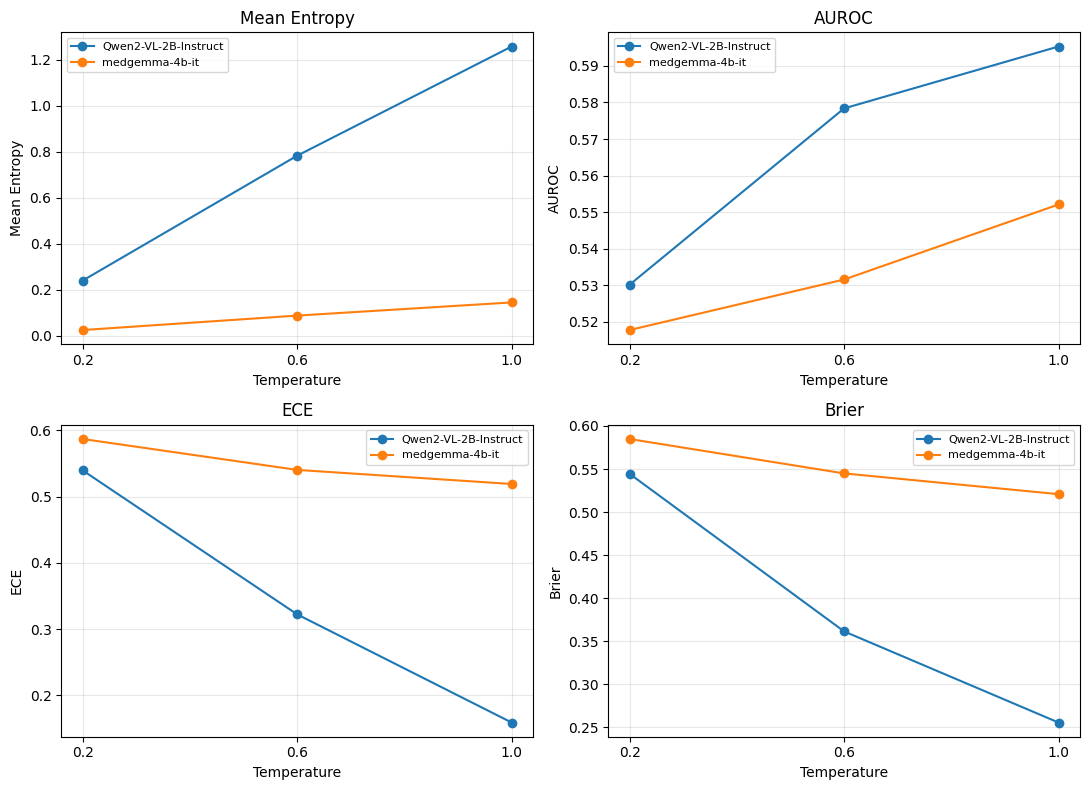

'\nChanges:\n* Only the variable names and the save location change. The figure now goes to outputs/ with the agreed file name.\n'

In [ ]:
metrics = ["Mean Entropy", "AUROC", "ECE", "Brier"]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, metric in zip(axes.flatten(), metrics):
    for model in models9:
        data = q9[q9["Model"] == model]

        ax.plot(data["Temperature"], data[metric],
                marker="o", label=model)

    ax.set_title(metric)
    ax.set_xlabel("Temperature")
    ax.set_ylabel(metric)
    ax.set_xticks(temps9)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/q9_qwen2-vl-2b_medgemma-4b-it_metrics_vs_temp.png", dpi=300)
plt.show()

'''
Changes:
* Only the variable names and the save location change. The figure now goes to outputs/ with the agreed file name.
'''

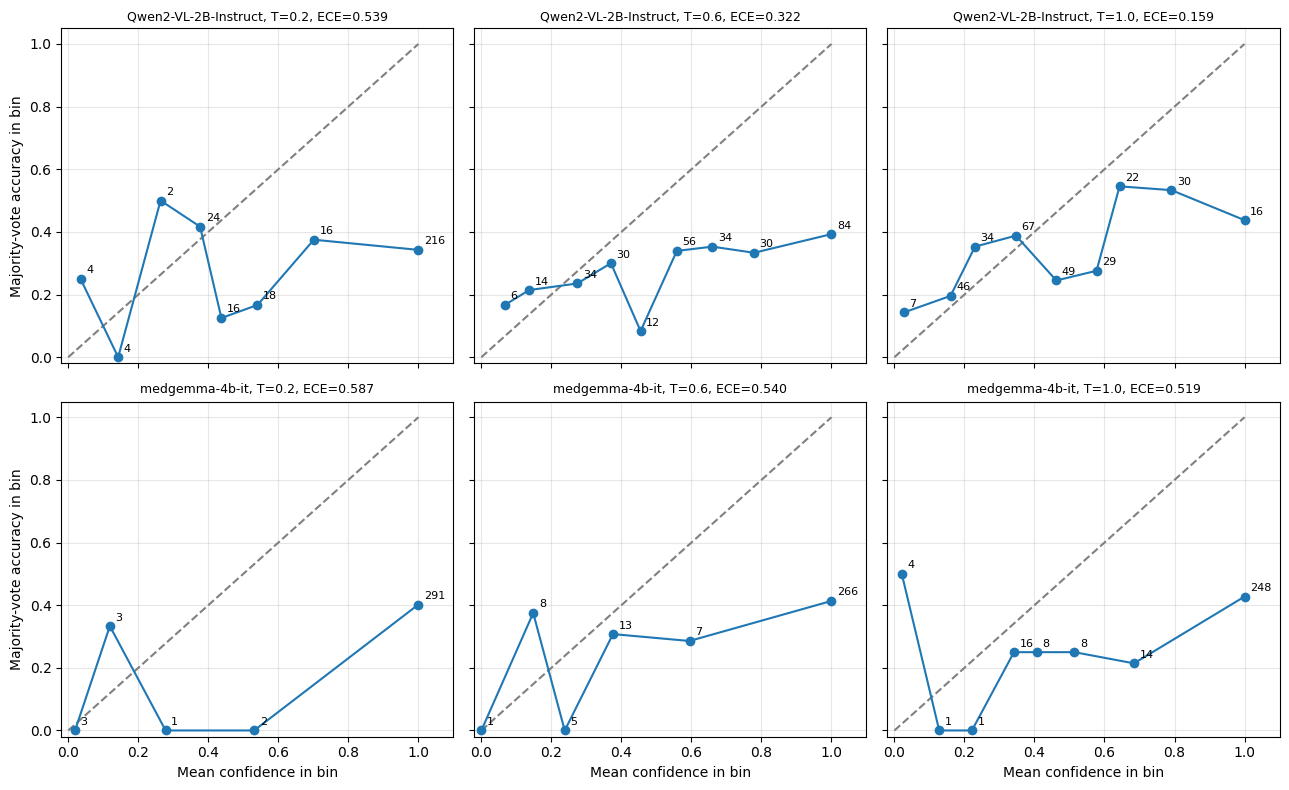

'\nNew cell:\n* Draws reliability diagrams, accuracy against confidence for each bin with question counts, one panel per model and temperature. These show why ECE and Brier change with temperature.\n* The rightmost point in each panel (confidence 1.0) is exactly the group of unanimous questions.\n* The assert makes sure the plotted bins add up to the same ECE as the table.\n'

In [ ]:
#Q9 reliability diagrams
fig, axes = plt.subplots(len(models9), len(temps9), figsize=(13, 8), sharex=True, sharey=True)

for i, model in enumerate(models9):
    for j, temp in enumerate(temps9):
        u, corr = se9[(model, temp)]
        tab = bin_table(se_norm(u), corr, 10)  # same normalisation and bins as compute_calibration_metrics
        ece = q9.loc[(q9["Model"] == model) & (q9["Temperature"] == temp), "ECE"].iloc[0]
        assert np.isclose(tab["weighted_gap"].sum(), ece)
        ax = axes[i, j]
        ax.plot([0, 1], [0, 1], "--", color="grey")
        ax.plot(tab["mean_conf"], tab["accuracy"], marker="o")
        for _, r in tab.iterrows():
            ax.annotate(int(r["n"]), (r["mean_conf"], r["accuracy"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
        ax.set_title(f"{model}, T={temp}, ECE={ece:.3f}", fontsize=9)
        ax.set_xlim(-0.02, 1.1)
        ax.set_ylim(-0.02, 1.05)
        ax.grid(alpha=0.3)
        if i == len(models9) - 1:
            ax.set_xlabel("Mean confidence in bin")
        if j == 0:
            ax.set_ylabel("Majority-vote accuracy in bin")

plt.tight_layout()
plt.savefig("outputs/q9_qwen2-vl-2b_medgemma-4b-it_reliability_by_temp.png", dpi=300)
plt.show()

'''
New cell:
* Draws reliability diagrams, accuracy against confidence for each bin with question counts, one panel per model and temperature. These show why ECE and Brier change with temperature.
* The rightmost point in each panel (confidence 1.0) is exactly the group of unanimous questions.
* The assert makes sure the plotted bins add up to the same ECE as the table.
'''

                      n_questions samples_per_question  majority_acc  mean_SE  n_SE0
model                                                                               
GPT-5-mini                    225                 5-10         0.693    0.118    189
Qwen2.5-VL-32B T=1.0          225                10-10         0.573    0.538    104
Qwen2-VL-2B T=1.0             225                10-10         0.387    1.206     14
medgemma-4b-it T=1.0          225                10-10         0.409    0.149    184

all four majority answers wrong: 26 | all four agree: 39 | all four correct: 34 | questions with 10 gpt-5-mini samples: 170

Case 1: shared error: index 2652 | gold D | X-ray | Disease Diagnosis | Image level | Obstetrics and Gynecology
question: View the image provided. What is the likely abnormal condition demonstrated?
options: [A] normal mammography scans | [B] well defined circumscribed masses | [C] architectural distortion | [D] calcification
                     votes maj corre

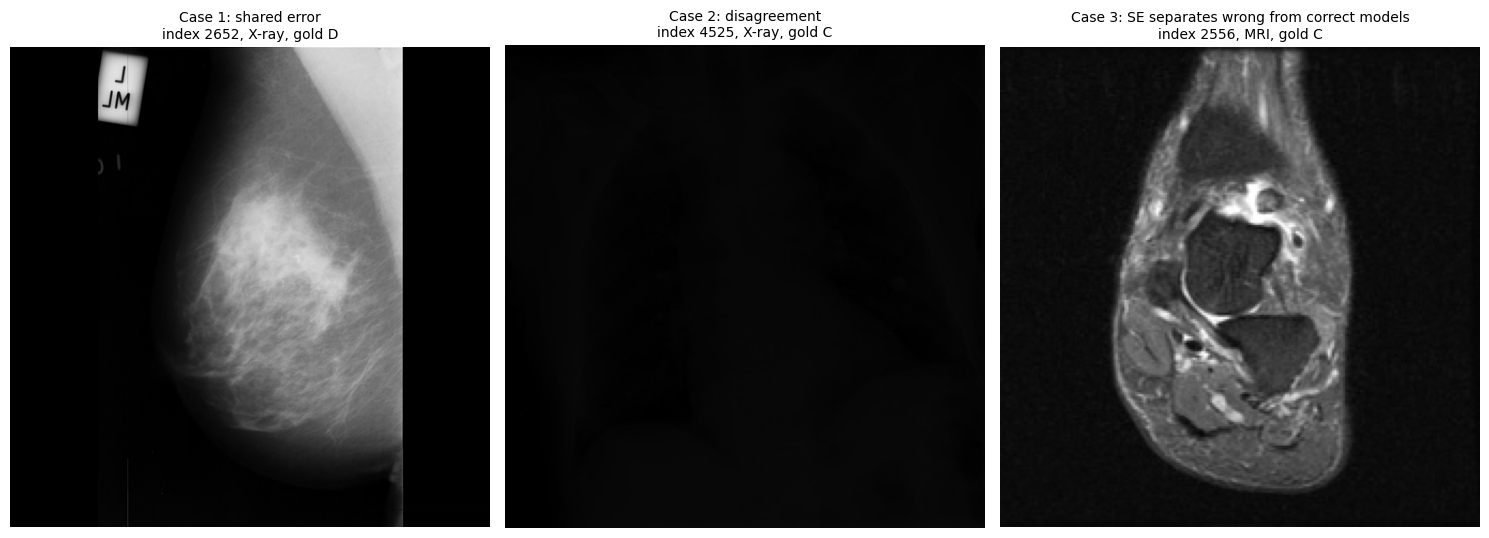

In [ ]:
#Q14
import matplotlib.pyplot as plt

files14 = {
    "GPT-5-mini": "data/model_responses/outputs_gpt5-mini_no-logprobs.tsv",
    "Qwen2.5-VL-32B T=1.0": "data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_1.0.tsv",
    "Qwen2-VL-2B T=1.0": "data/model_responses/outputs_Qwen2-VL-2B-Instruct-temp_1.0.tsv",
    "medgemma-4b-it T=1.0": "data/model_responses/outputs_medgemma-4b-it-temp_1.0.tsv",
}
d14 = {m: load_and_process_data(p) for m, p in files14.items()}

def per_question(d):
    """Majority answer, correctness, semantic entropy and vote counts per question, with the notebook's vote rule."""
    rows = []
    for idx, g in d.groupby("index"):
        votes = Counter(g["parsed_response"])
        maj = votes.most_common(1)[0][0]  # ties go to the first-encountered answer, None counts as a vote
        p = np.array(list(votes.values())) / len(g)
        rows.append({"index": idx, "maj": maj, "correct": int(maj == g["gold_label"].iloc[0]),
                     "SE": round(-np.sum(p * np.log2(p)), 10) + 0.0, "n": len(g),
                     "votes": ", ".join(f"{k}:{v}" for k, v in votes.most_common())})
    return pd.DataFrame(rows).set_index("index")

res14 = {}
for m, d in d14.items():
    q = per_question(d)
    se, corr, _ = compute_semantic_entropy_uncertainty(d)
    assert np.allclose(q["SE"], se) and (q["correct"].values == corr).all()
    res14[m] = q

common14 = res14["GPT-5-mini"].index  # the 225 questions gpt-5-mini covers
for m in res14:
    res14[m] = res14[m].loc[common14].copy()
    res14[m]["SE_pct"] = res14[m]["SE"].rank(pct=True)  # percentile within the model, over the 225 questions

print(pd.DataFrame([{"model": m, "n_questions": len(q), "samples_per_question": f"{q['n'].min()}-{q['n'].max()}",
                     "majority_acc": round(q["correct"].mean(), 3), "mean_SE": round(q["SE"].mean(), 3),
                     "n_SE0": int((q["SE"] == 0).sum())} for m, q in res14.items()]).set_index("model").to_string())

maj14 = pd.DataFrame({m: q["maj"].astype(str) for m, q in res14.items()})
cor14 = pd.DataFrame({m: q["correct"] for m, q in res14.items()})
pct14 = pd.DataFrame({m: q["SE_pct"] for m, q in res14.items()})
n_correct = cor14.sum(axis=1)
feat14 = pd.DataFrame({
    "gpt10": res14["GPT-5-mini"]["n"] == 10,
    "mean_SE": pd.DataFrame({m: q["SE"] for m, q in res14.items()}).mean(axis=1),
    "n_distinct": maj14.nunique(axis=1),
    "same_wrong": (n_correct == 0) & (maj14.nunique(axis=1) == 1),
    "gap": pct14.where(cor14 == 0).mean(axis=1) - pct14.where(cor14 == 1).mean(axis=1),  # wrong minus correct models
})
print(f"\nall four majority answers wrong: {(n_correct == 0).sum()} | all four agree: {(feat14['n_distinct'] == 1).sum()} "
      f"| all four correct: {(n_correct == 4).sum()} | questions with 10 gpt-5-mini samples: {feat14['gpt10'].sum()}")

def pick(mask, by, asc, exclude=()):
    # pre-specified ranking, then questions with 10 gpt-5-mini samples, then lowest index
    c = feat14[mask & ~feat14.index.isin(exclude)].reset_index()
    return int(c.sort_values(by + ["gpt10", "index"], ascending=asc + [False, True]).iloc[0]["index"])

cases14 = {}
if (n_correct == 0).any():
    cases14["Case 1: shared error"] = pick(n_correct == 0, ["same_wrong", "mean_SE"], [False, True])
else:
    print("no question is answered incorrectly by all four models")
    cases14["Case 1: most models wrong, most disagreement"] = pick(n_correct == n_correct.min(), ["n_distinct", "mean_SE"], [False, True])
cases14["Case 2: disagreement"] = pick(feat14["n_distinct"] > 1, ["n_distinct", "mean_SE"], [False, True], list(cases14.values()))
cases14["Case 3: SE separates wrong from correct models"] = pick(n_correct.between(1, 3), ["gap"], [False], list(cases14.values()))

ds14 = pd.read_csv("data/GMAI_mm_bench_dataset.tsv", sep="\t").set_index("index")
for name, i in cases14.items():
    r = ds14.loc[i]
    print(f"\n{'=' * 110}\n{name}: index {i} | gold {r['answer']} | {r['modality']} | {r['clinical VQA task']} "
          f"| {r['perceptual granularity']} | {r['department']}")
    print(f"question: {r['question']}")
    print("options: " + " | ".join(f"[{k}] {r[k]}" for k in "ABCDE" if pd.notna(r[k])))
    tab = pd.DataFrame({m: q.loc[i] for m, q in res14.items()}).T[["votes", "maj", "correct", "SE", "SE_pct", "n"]]
    tab[["SE", "SE_pct"]] = tab[["SE", "SE_pct"]].astype(float).round(3)
    print(tab.to_string())
    for m, d in d14.items():
        print(f"\n  {m}, one response per distinct answer:")
        for a, resp in d[d["index"] == i].drop_duplicates("parsed_response")[["parsed_response", "response"]].values:
            print(f"    {a!s:>4}  {resp!r}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, (name, i) in zip(axes, cases14.items()):
    ax.imshow(Image.open(os.path.join("data/images", ds14.loc[i, "image_path"])), cmap="gray")
    ax.set_title(f"{name}\nindex {i}, {ds14.loc[i, 'modality']}, gold {ds14.loc[i, 'answer']}", fontsize=10)
    ax.axis("off")
plt.tight_layout()
os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/q14_four_models_case_images.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
#Q14 optional: discrimination and calibration of each model on the same 225 questions
rows14 = []
for m, d in d14.items():
    u, corr, _ = compute_semantic_entropy_uncertainty(d[d["index"].isin(common14)])
    auroc, ece, brier = compute_calibration_metrics(u, corr)  # min-max normalisation per model, 10 bins
    rows14.append({"model": m, "n_questions": len(corr), "majority_acc": corr.mean(), "AUROC": auroc, "ECE": ece, "Brier": brier})
print(pd.DataFrame(rows14).set_index("model").round(4).to_string())

                      n_questions  majority_acc   AUROC     ECE   Brier
model                                                                  
GPT-5-mini                    225        0.6933  0.6375  0.2258  0.2382
Qwen2.5-VL-32B T=1.0          225        0.5733  0.7011  0.1788  0.2476
Qwen2-VL-2B T=1.0             225        0.3867  0.6039  0.1663  0.2610
medgemma-4b-it T=1.0          225        0.4089  0.5518  0.5076  0.5093


In [ ]:
#Q18
from sklearn.model_selection import train_test_split

d18 = load_and_process_data("data/model_responses/outputs_Qwen2.5-VL-32B-Instruct-temp_1.0.tsv")
se18, corr18, _ = compute_semantic_entropy_uncertainty(d18)
q18 = pd.DataFrame({"SE": se18.round(10) + 0.0, "correct": corr18}, index=sorted(d18["index"].unique()))  # rounded so equal vote splits tie exactly, + 0.0 removes -0.0
q18.index.name = "index"
q18["modality"] = d18.groupby("index")["modality"].first()

val_idx18, _ = train_test_split(q18.index, test_size=0.5, stratify=q18["modality"], random_state=0)  # split by question, so all samples stay together
q18["split"] = np.where(q18.index.isin(val_idx18), "val", "test")
val18, test18 = q18[q18["split"] == "val"], q18[q18["split"] == "test"]
print(pd.crosstab(q18["split"], q18["modality"], margins=True).to_string())

def refer_stats(q, tau):
    ref = q["SE"] > tau  # questions with the same SE always get the same decision
    ans = q.loc[~ref, "correct"]
    return {"tau": tau, "n_referred": int(ref.sum()), "referral": ref.mean(), "coverage": 1 - ref.mean(),
            "acc_answered": ans.mean(), "unflagged_errors": int((ans == 0).sum())}

cands18 = pd.DataFrame([refer_stats(val18, t) for t in np.sort(val18["SE"].unique())])  # tau = max SE refers nothing
cands18["n_at_tau"] = [int((val18["SE"] == t).sum()) for t in cands18["tau"]]
cands18["feasible"] = cands18["referral"] <= 0.2
best18 = cands18[cands18["feasible"]].sort_values(["acc_answered", "tau"], ascending=[False, False]).iloc[0]  # equal accuracy: refer fewer
tau18 = best18["tau"]
print(f"\nvalidation: {len(val18)} questions, full-coverage accuracy {val18['correct'].mean():.4f}")
print(cands18.round(4).to_string(index=False))
print(f"\nselected threshold: refer if SE > {tau18:.4f} bits")

res18 = refer_stats(test18, tau18)
print(f"\ntest: {len(test18)} questions, full-coverage accuracy {test18['correct'].mean():.4f}, "
      f"incorrect without referral {int((test18['correct'] == 0).sum())}")
print(pd.DataFrame([best18.drop(["n_at_tau", "feasible"]).to_dict(), res18], index=["validation", "test"]).round(4).to_string())

k18 = res18["n_referred"]
rng18 = np.random.default_rng(0)
rand18 = []
for _ in range(1000):
    keep = np.delete(test18["correct"].values, rng18.choice(len(test18), size=k18, replace=False))
    rand18.append({"acc_answered": keep.mean(), "unflagged_errors": int((keep == 0).sum())})
rand18 = pd.DataFrame(rand18)
print(f"\nrandom referral of the same {k18} test questions, 1000 repeats:")
print(rand18.describe(percentiles=[0.025, 0.975]).loc[["mean", "std", "min", "2.5%", "97.5%", "max"]].round(4).to_string())
print(f"share of random draws with accuracy among answered >= uncertainty-based: {(rand18['acc_answered'] >= res18['acc_answered']).mean():.3f}")

q18["referred"] = q18["SE"] > tau18
os.makedirs("outputs", exist_ok=True)
q18.reset_index()[["index", "split", "modality", "SE", "correct", "referred"]].to_csv("outputs/q18_qwen2.5-vl-32b_t1.0_se_referral.csv", index=False)

modality   CT  MRI  X-ray  All
split                         
test       50   50     50  150
val        50   50     50  150
All       100  100    100  300

validation: 150 questions, full-coverage accuracy 0.5267
   tau  n_referred  referral  coverage  acc_answered  unflagged_errors  n_at_tau  feasible
0.0000          89    0.5933    0.4067        0.6557                21        61     False
0.4690          74    0.4933    0.5067        0.6711                25        15     False
0.7219          64    0.4267    0.5733        0.6512                30        10     False
0.8813          51    0.3400    0.6600        0.6162                38        13     False
0.9219          49    0.3267    0.6733        0.6040                40         2     False
0.9710          42    0.2800    0.7200        0.5833                45         7     False
1.0000          37    0.2467    0.7533        0.5841                47         5     False
1.1568          30    0.2000    0.8000        0.5833       

In [ ]:
#Q18 optional: sensitivity of the threshold and the test referral rate to the split
rows18 = []
for s in range(20):
    v_idx, _ = train_test_split(q18.index, test_size=0.5, stratify=q18["modality"], random_state=s)
    v, t = q18[q18.index.isin(v_idx)], q18[~q18.index.isin(v_idx)]
    c = pd.DataFrame([refer_stats(v, x) for x in np.sort(v["SE"].unique())])
    b = c[c["referral"] <= 0.2].sort_values(["acc_answered", "tau"], ascending=[False, False]).iloc[0]
    r = refer_stats(t, b["tau"])
    rows18.append({"seed": s, "tau": b["tau"], "val_referral": b["referral"], "test_referral": r["referral"],
                   "test_acc_answered": r["acc_answered"], "test_acc_full": t["correct"].mean()})
rows18 = pd.DataFrame(rows18)
print(rows18.round(4).to_string(index=False))
print(f"\nsplits where the test referral exceeds 20%: {(rows18['test_referral'] > 0.2).sum()} of {len(rows18)}")
print(f"splits where referral raises test accuracy: {(rows18['test_acc_answered'] > rows18['test_acc_full']).sum()} of {len(rows18)}")

 seed    tau  val_referral  test_referral  test_acc_answered  test_acc_full
    0 1.1568        0.2000         0.2200             0.5556         0.5067
    1 1.1568        0.1867         0.2333             0.6174         0.5467
    2 1.1568        0.1867         0.2333             0.6087         0.5267
    3 1.3610        0.1067         0.1067             0.5149         0.4933
    4 1.8464        0.0200         0.0200             0.5306         0.5200
    5 1.1568        0.1867         0.2333             0.5391         0.4933
    6 1.3568        0.1200         0.1533             0.5354         0.5133
    7 1.3610        0.1000         0.1133             0.5263         0.5200
    8 1.3610        0.1067         0.1067             0.5746         0.5467
    9 1.3610        0.0867         0.1267             0.5573         0.5333
   10 1.1568        0.2000         0.2200             0.5983         0.5533
   11 1.3568        0.1467         0.1267             0.5496         0.5467
   12 1.2955

### Question 16

In [ ]:
from transformers import AutoModelForImageTextToText, AutoProcessor

qwen_id = "Qwen/Qwen2-VL-2B-Instruct"
qwen_processor = AutoProcessor.from_pretrained(qwen_id)
qwen = AutoModelForImageTextToText.from_pretrained(qwen_id, dtype="auto", device_map="auto").eval()

LETTERS = "ABCDE"
load_image = lambda path: Image.open(os.path.join("data/images", path))
os.makedirs("outputs", exist_ok=True)

def sample_answers(row, image, n=10):
    content = [{"type": "text", "text": construct_prompt(row)}] + ([{"type": "image"}] if image is not None else [])
    prompt = qwen_processor.apply_chat_template([{"role": "user", "content": content}], add_generation_prompt=True)
    inputs = qwen_processor(text=[prompt] * n, images=[image] * n if image is not None else None, return_tensors="pt").to(qwen.device)

    with torch.no_grad():
        out = qwen.generate(**inputs, max_new_tokens=32, do_sample=True, temperature=1.0, top_p=0.9,
                            top_k=0, pad_token_id=qwen_processor.tokenizer.pad_token_id)

    return qwen_processor.batch_decode(out[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)


# 50 fixed questions with >= 4 options
questions = add_options_dict(pd.read_csv("data/GMAI_mm_bench_dataset.tsv", sep="\t"))
questions["num_options"] = questions["options"].apply(len)
subset = questions[questions["num_options"] >= 4].sample(50, random_state=0)
print(subset["perceptual granularity"].value_counts())

def run(make_input, name, seed):
    path = f"outputs/{name}.tsv"
    if os.path.exists(path):  # reload a finished condition instead of regenerating it
        d = pd.read_csv(path, sep="\t")
        d["parsed_response"] = pd.Series([a if isinstance(a, str) else None for a in d["parsed_response"]], dtype=object)
        return d

    torch.manual_seed(seed)
    rows = []

    for _, row in tqdm(subset.iterrows(), total=len(subset)):
        shown, image, to_orig = make_input(row)
        for resp in sample_answers(shown, image):
            letter = parse_response(resp)
            rows.append({"index": row["index"], "gold_label": row["answer"], "num_options": row["num_options"],
                         "parsed_response": to_orig.get(letter, letter), "response": resp,
                         "perceptual granularity": row["perceptual granularity"], "shown_to_original": to_orig,
                         "image_path": os.path.basename(image.filename) if image is not None else None})

    d = pd.DataFrame(rows)
    d.to_csv(path, sep="\t", index=False)
    return d

def majority(d):
    return d.groupby("index")["parsed_response"].agg(lambda s: Counter(s).most_common(1)[0][0]).fillna("none")

def summarize(results):
    table = {}

    for name, d in results.items():
        u, c, _ = compute_semantic_entropy_uncertainty(d)
        auroc, ece, brier = compute_calibration_metrics(u, c)
        table[name] = {"accuracy": c.mean(), "mean SE": u.mean(), "AUROC": auroc, "ECE": ece, "Brier": brier,
                       "unparseable": int(d["parsed_response"].isna().sum())}  # counted as a separate, incorrect answer
    t = pd.DataFrame(table).T
    print("\n" + t.round(3).to_string())
    print(f"\nchange vs {t.index[0]}\n" + (t - t.iloc[0]).iloc[1:, :5].round(3).to_string())

original = lambda row: (row, load_image(row["image_path"]), {L: L for L in row["options"]})

'''
What changed and why:

* run saves each condition to outputs/ under the agreed file names, and reloads it on a second run, so a dropped session doesn’t lose work.
* Each condition sets its own seed inside run, so every condition can be reproduced on its own.
* Each saved row records the letter mapping and the image used, so the files show which option order and which unrelated image every answer came from.
* summarize prints the unparseable count per condition. Without it, the no-image results can’t be interpreted.
* Also, summarize prints the change against the first condition, since Q16 asks for changes.
'''

preprocessor_config.json:   0%|          | 0.00/347 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

perceptual granularity
Image level      27
Contour level    12
Mask level        8
Box level         3
Name: count, dtype: int64


In [9]:
rng = np.random.default_rng(0)
perms = {}

for _, row in subset.iterrows():
    letters, chosen = list(row["options"]), []

    while len(chosen) < 3:
        p = [str(x) for x in rng.permutation(letters)]
        if p != letters and p not in chosen:
            chosen.append(p)

    # original letter shown at position i
    perms[row["index"]] = chosen

def shuffled(k):
    def make(row):
        p, new = perms[row["index"]][k], row.copy()

        for i, orig in enumerate(p):
            new[LETTERS[i]] = row["options"][orig]

        return new, load_image(row["image_path"]), {LETTERS[i]: orig for i, orig in enumerate(p)}
    return make

q16 = {"original": run(original, "q16_qwen2-vl-2b_responses_perm0", 0),
       "original (re-run)": run(original, "q16_qwen2-vl-2b_responses_perm0_rerun", 100)}

for k in range(3):
    q16[f"permutation {k+1}"] = run(shuffled(k), f"q16_qwen2-vl-2b_responses_perm{k+1}", k + 1)
summarize(q16)

maj = {name: majority(d) for name, d in q16.items()}

for name in list(q16)[1:]:
    print(f"{name}: majority answer differs from original on {(maj[name] != maj['original']).mean():.2f} of questions")

# example: re-run agrees with the original, but a permutation changes the chosen answer
ex = next((i for i in maj["original"].index if maj["original (re-run)"][i] == maj["original"][i]
           and any(maj[f"permutation {k+1}"][i] != maj["original"][i] for k in range(3))), None)

if ex is not None:
    row = subset.set_index("index").loc[ex]
    print(f"\nQuestion {ex}: {row['question']}\noptions: {row['options']}, gold: {row['answer']}")
    for name, d in q16.items():
        order = "ABCDE"[:row["num_options"]] if name.startswith("original") else "".join(perms[ex][int(name[-1]) - 1])
        group = d[d["index"] == ex]
        print(f"{name} (shown order {order}): votes by content {dict(Counter(row['options'].get(a, a) for a in group['parsed_response']))} | e.g. {group['response'].iloc[0]!r}")

'''
What changed and why:

* Each run call now has its file name and seed, matching the decisions log: original 0, re-run 100, permutations 1–3. This replaces the single torch.manual_seed(0) before all five runs.
* The example prints votes as option text instead of letters. The sample response still shows the letter the model saw, so letters alone were easy to misreport.
'''

100%|██████████| 50/50 [06:43<00:00,  8.07s/it]


                   accuracy  mean SE  AUROC    ECE  Brier  unparseable
original               0.30    1.258  0.465  0.256  0.310          7.0
original (re-run)      0.28    1.316  0.523  0.220  0.268          7.0
permutation 1          0.28    1.357  0.573  0.241  0.244          5.0
permutation 2          0.20    1.336  0.552  0.247  0.255          2.0
permutation 3          0.34    1.413  0.555  0.174  0.244          2.0

change vs original
                   accuracy  mean SE  AUROC    ECE  Brier
original (re-run)     -0.02    0.057  0.058 -0.036 -0.042
permutation 1         -0.02    0.099  0.109 -0.016 -0.065
permutation 2         -0.10    0.078  0.088 -0.010 -0.055
permutation 3          0.04    0.155  0.090 -0.082 -0.065
original (re-run): majority answer differs from original on 0.20 of questions
permutation 1: majority answer differs from original on 0.52 of questions
permutation 2: majority answer differs from original on 0.56 of questions
permutation 3: majority answer differ

### Question 17

In [10]:
unrelated = {}
norm = lambda s: str(s).lower().strip().rstrip(".")
dept = questions["department"].fillna("none")

for _, row in subset.iterrows():
    # different modality, different department, donor label not among the options
    opts = {norm(o) for o in row["options"].values()}
    pool = questions[(questions["modality"] != row["modality"]) & (dept != dept[row.name])
                     & ~questions["category"].map(norm).isin(opts)]
    unrelated[row["index"]] = pool.sample(1, random_state=int(row["index"]))["image_path"].iloc[0]

same = lambda row: {L: L for L in row["options"]}

q17 = {"original image": q16["original"],
       "no image": run(lambda row: (row, None, same(row)), "q17_qwen2-vl-2b_responses_noimage", 4),
       "unrelated image": run(lambda row: (row, load_image(unrelated[row["index"]]), same(row)),
                              "q17_qwen2-vl-2b_responses_unrelated", 5)}
summarize(q17)
print(f"chance level (mean 1/number of options): {(1 / subset['num_options']).mean():.3f}")

maj17 = {name: majority(d) for name, d in q17.items()}
gold = q17["original image"].groupby("index")["gold_label"].first()
gran = q17["original image"].groupby("index")["perceptual granularity"].first()

for name in ["no image", "unrelated image"]:
    print(f"{name}: same majority answer as with the original image on {(maj17[name] == maj17['original image']).mean():.2f}")

se = {name: pd.Series(compute_semantic_entropy_uncertainty(d)[0], index=sorted(d["index"].unique())) for name, d in q17.items()}
acc = pd.DataFrame({name: (m == gold).groupby(gran).mean() for name, m in maj17.items()})
acc = acc.join(pd.DataFrame({f"SE {name}": s.groupby(gran).mean() for name, s in se.items()}))
acc["n"] = gran.value_counts()

print("\naccuracy and mean SE by perceptual granularity:")
print(acc.round(2).to_string())

'''
What changed and why:

* The unrelated-image pool follows this rule now: different modality, different department (a missing department counts as its own group), and a donor label that isn’t any of the question’s options. This fixes the same-modality pairing, such as a chest X-ray with another chest X-ray.
* Each condition has its own file name and seed: no image 4, unrelated 5.
* The chance level is printed, because the prediction is judged against it.
* Mean Semantic Entropy per granularity group is added next to accuracy, since the question asks to compare accuracy and uncertainty.
'''

100%|██████████| 50/50 [08:12<00:00,  9.86s/it]


                 accuracy  mean SE  AUROC    ECE  Brier  unparseable
original image       0.30    1.258  0.465  0.256  0.310          7.0
no image             0.00    1.685    NaN  0.424  0.255        187.0
unrelated image      0.16    1.400  0.484  0.249  0.254          4.0

change vs original image
                 accuracy  mean SE  AUROC    ECE  Brier
no image            -0.30    0.427    NaN  0.167 -0.054
unrelated image     -0.14    0.142  0.019 -0.007 -0.056
chance level (mean 1/number of options): 0.238
no image: same majority answer as with the original image on 0.26
unrelated image: same majority answer as with the original image on 0.60

accuracy and mean SE by perceptual granularity:
                        original image  no image  unrelated image  SE original image  SE no image  SE unrelated image   n
perceptual granularity                                                                                                   
Box level                         0.00       0.0  


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(



needs the image | question 941: Observe the X-ray image. What is the most likely abnormality shown in the highlight area? 
options: {'A': 'retinal hemorrhages', 'B': 'esophageal cancer', 'C': 'rib fracture', 'D': 'pulmonary fibrosis'}, gold: C, unrelated image: 3145.jpg
original image: votes {'B': 1, 'D': 4, 'C': 5}, SE 1.36, example '[B]'
no image: votes {'A': 2, None: 5, 'B': 2, 'D': 1}, SE 1.76, example '[A]'
unrelated image: votes {'B': 4, 'D': 3, 'A': 2, 'C': 1}, SE 1.85, example '[B] esophageal cancer'


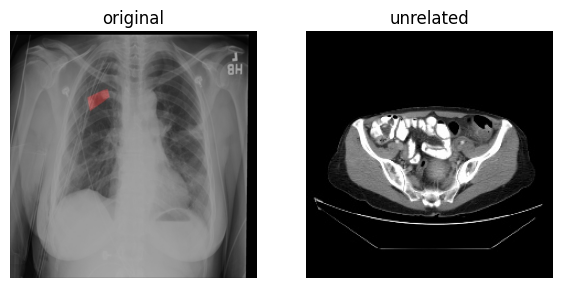


unrelated image changes the answer | question 3035: Observe the image. What is the most likely abnormality shown in the picture? 
options: {'A': 'liver lesion', 'B': 'hip marrow inflammation', 'C': 'pancreatic lesion', 'D': 'ankle or foot soft tissue mass'}, gold: B, unrelated image: 3145.jpg
original image: votes {'B': 5, 'D': 5}, SE 1.00, example '[B]'
no image: votes {'D': 2, 'B': 2, None: 5, 'A': 1}, SE 1.76, example '[D]'
unrelated image: votes {'D': 8, 'B': 1, 'A': 1}, SE 0.92, example '[D] ankle or foot soft tissue mass'


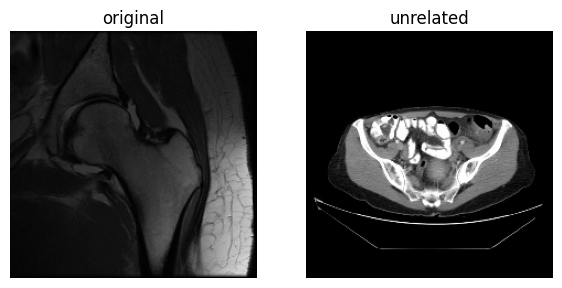

'\nWhat changed and why:\n\n* Case 3 follows the following rule: among questions whose majority answer changes with the unrelated image, take the one with the lowest Semantic Entropy. Their rule picked a question the model got wrong with the original image too, which says nothing about the unrelated image.\n* A missing case is skipped instead of crashing.\nThe unrelated image’s file name is printed, so the report can state which image was used.\n* Each case figure is saved to outputs/.\n'

In [14]:
correct = {name: maj17[name] == gold for name in q17}

se = {name: pd.Series(compute_semantic_entropy_uncertainty(d)[0], index=sorted(d["index"].unique())) for name, d in q17.items()}

case_1 = next((i for i in gold.index if correct["original image"][i] and not correct["no image"][i] and not correct["unrelated image"][i]), None)
case_2 = next((i for i in gold.index if correct["no image"][i]), None)
changed = se["unrelated image"][maj17["unrelated image"] != maj17["original image"]]
case_3 = changed.idxmin() if len(changed) else None  # lowest SE among answers changed by the unrelated image

meta = subset.set_index("index")
for label, i in [("needs the image", case_1), ("correct without image", case_2), ("unrelated image changes the answer", case_3)]:
    if i is None:
        continue
    row = meta.loc[i]
    print(f"\n{label} | question {i}: {row['question']} \noptions: {row['options']}, gold: {row['answer']}, unrelated image: {unrelated[i]}")

    for name, d in q17.items():
        g = d[d["index"] == i]
        print(f"{name}: votes {dict(Counter(g['parsed_response']))}, SE {se[name][i]:.2f}, example {g['response'].iloc[0]!r}")

    fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))
    ax[0].imshow(load_image(row["image_path"])); ax[0].set_title("original")
    ax[1].imshow(load_image(unrelated[i])); ax[1].set_title("unrelated")
    for a in ax: a.axis("off")
    fig.savefig(f"outputs/q17_qwen2-vl-2b_case_{i}.png", dpi=200)
    plt.show()

'''
What changed and why:

* Case 3 follows the following rule: among questions whose majority answer changes with the unrelated image, take the one with the lowest Semantic Entropy. Their rule picked a question the model got wrong with the original image too, which says nothing about the unrelated image.
* A missing case is skipped instead of crashing.
The unrelated image’s file name is printed, so the report can state which image was used.
* Each case figure is saved to outputs/.
'''